In [ ]:
%load_ext autoreload
%autoreload 2

### Figure 3: MS synthetic experiments results.

 - __a)__ In-distribution MS updating mAP barplots.
 - __b)__ Per-allele AP difference distributions to the next model.
 - __c)__ Steps per model updating method.
 - __d)__ Cluster-specific updating performance on regular negative background.
 - __e)__ Cluster-specific updating performance on hard negative background.
 - __f)__ Cluster-specific distance to performance drop scatterplot.
 - __g)__ Lambda controllability test on A*02:01 cluster 1.
 - __h)__ Unseen allele updating.

__Note:__ Axis labels and smaller formatting done in Adobe Illustrator.

In [ ]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT.name != "CLSBN26":
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError("Could not find CLSBN26 project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "Data"
SRC_DIR = PROJECT_ROOT / "src"
FIGURES_DIR = PROJECT_ROOT / "Figures"
MODEL_CHECKPOINTS_DIR = PROJECT_ROOT / "Model_Checkpoints"

print("PROJECT_ROOT:", PROJECT_ROOT)
print("PROJECT_ROOT in sys.path:", str(PROJECT_ROOT) in sys.path)

In [ ]:
# get mhc pseudosequences (process before you use)
from Data.mhc_pseudo_seqs import mhc_seq_dict
mhc_seq_dict={k.removeprefix("HLA-").replace("*","").replace(":",""):v for k,v in mhc_seq_dict.items()}

# imports
from src.general_utils import *
from src.get_feature_data import *
from src.plotting import *
from src.louvain_clustering import *

# misc
import warnings
warnings.filterwarnings("ignore")
device="cuda"

In [ ]:
"""
Set figure output directory
"""
# create central repository and for this figure
central_figure_dir="Figure3"

# associated data dir
associated_data_dir=f"{central_figure_dir}/Associated_Data"

### Fig. 3a: In-distribution MS updating mAP barplots

In [ ]:
# ms test set
datasets_dir = DATA_DIR / "Training_Datasets" / "Processed" / "MS_Train_Test_Sets"
ms_test_data=pd.read_csv(f"{datasets_dir}/ms_test_data.csv", index_col=0)

In [ ]:
# get performance of all models
split_percentages_dict={
    10: [0],
    20: [0, 1],
    30: [0, 1, 2],
    40: [0, 1, 2, 3],
    50: [0, 1, 2, 3, 4],
    60: [0, 1, 2, 3, 4, 5],
    70: [0, 1, 2, 3, 4, 5, 6],
    80: [0, 1, 2, 3, 4, 5, 6, 7],
    90: [0, 1, 2, 3, 4, 5, 6, 7, 8],
}

score_cols=["mhcprime", "ms_log_odds"]
score_cols+=[f"mhcprime_{str(pt_pct)}pct" for pt_pct in split_percentages_dict.keys()]
score_cols+=[f"mhcprime_{str(pt_pct)}pct_updated_on_10pct_ft" for pt_pct in split_percentages_dict.keys()]
score_cols+=[f"mhcprime_{str(pt_pct)}pct_updated_on_10pct_pepcl" for pt_pct in split_percentages_dict.keys()]
score_cols+=[f"ms_log_odds_{str(pt_pct)}" for pt_pct in split_percentages_dict.keys()]

ms_allele_ap_matrix=compute_ap_matrix_optimized(ms_test_data, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)

# create map df
ms_allele_map_matrix_df=pd.DataFrame(ms_allele_ap_matrix.mean(), columns=["ap"])
ms_allele_map_matrix_df.reset_index(inplace=True)
ms_allele_map_matrix_df.columns=["model_name", "ap"]

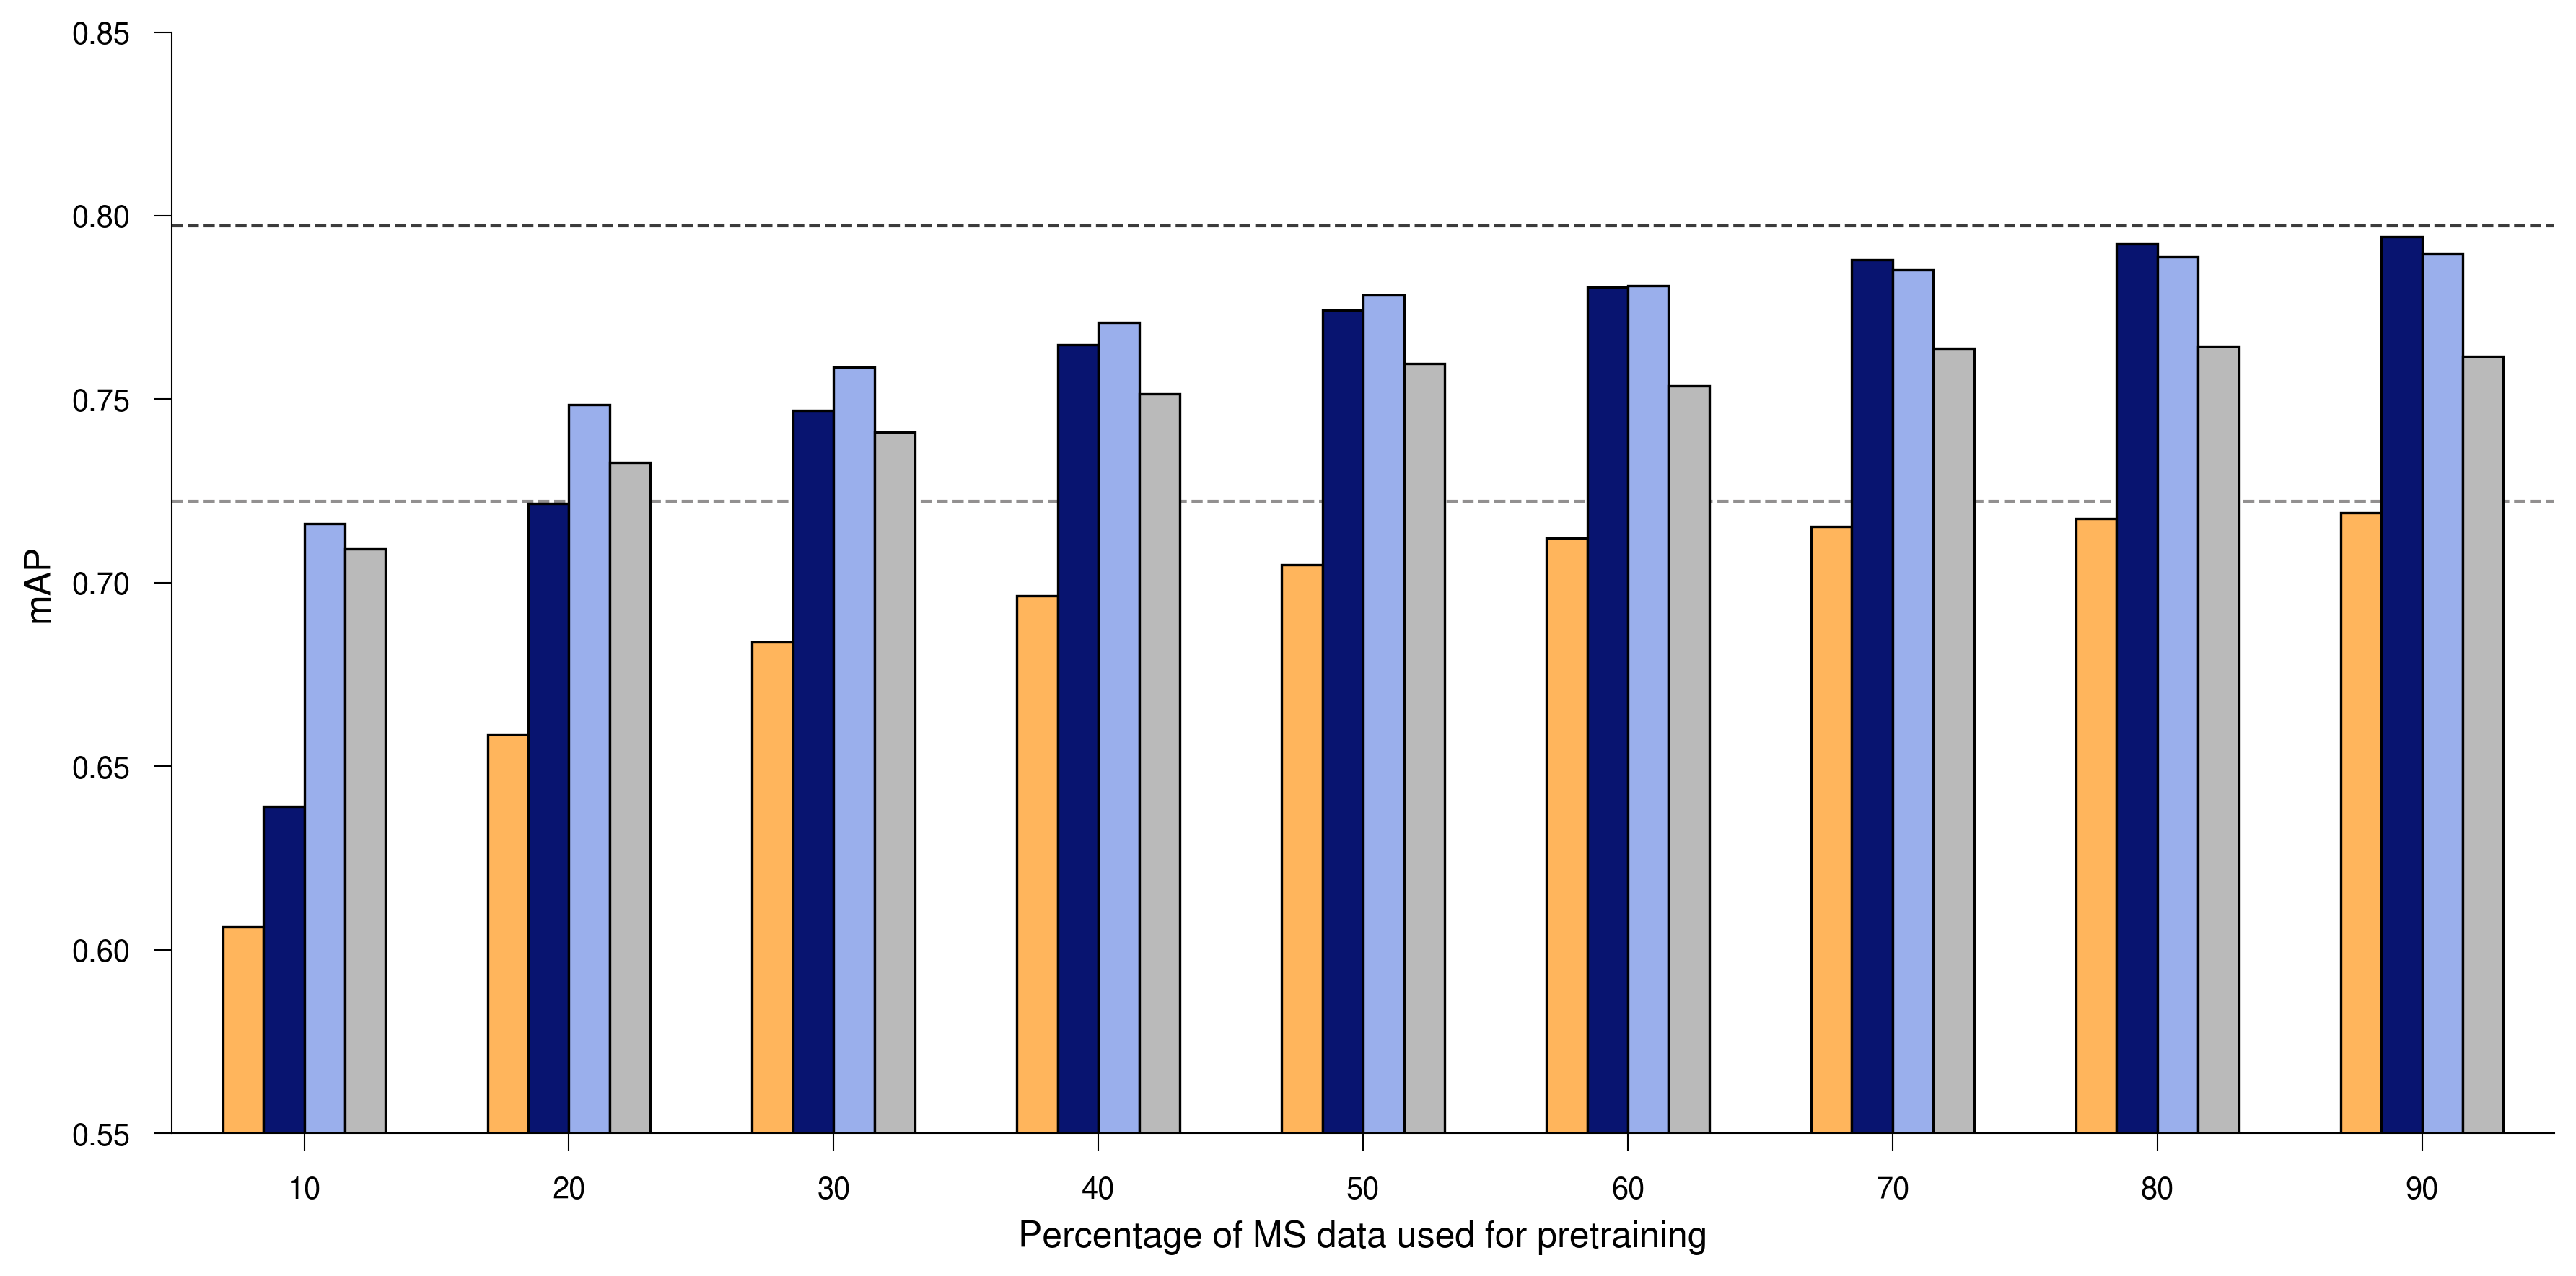

In [ ]:
# barplots
model_groups = {
    'Partial MS+ LO': [f"ms_log_odds_{str(pt_pct)}" for pt_pct in split_percentages_dict.keys()] + ["ms_log_odds"],
    'MHCPrime': [f"mhcprime_{str(pt_pct)}pct" for pt_pct in split_percentages_dict.keys()] + ["mhcprime"],
    'PepCL': [f"mhcprime_{str(pt_pct)}pct_updated_on_10pct_pepcl" for pt_pct in split_percentages_dict.keys()],
    'FT': [f"mhcprime_{str(pt_pct)}pct_updated_on_10pct_ft" for pt_pct in split_percentages_dict.keys()],
}

# x-axis values (epochs)
x_ticks = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]

# colors for each line
colors = {
    'MHCPrime': '#081470',
    'Partial MS+ LO': "#ffb55c", 
    'PepCL': "#9aafec",
    'FT': "#bababa",
}

# plot parameters
plot_params = {
    'title': '',
    'title_fontsize': 16,
    'title_bold': False,
    'xlabel': 'Percentage of MS data used for pretraining',
    'ylabel': 'mAP',
    'xlabel_fontsize': 12,
    'ylabel_fontsize': 12,
    'figsize': (12, 6),
    'dpi': 300,
    'legend_fontsize': 12,
    'legend_cols': 5,
    'legend_handle_size': 0.9,
    'marker_size': 3,
    'axis_linewidth': 0.5,
    'tick_length': 6.0,
    'xlabel_pad': 5.0,
    'ylabel_pad': 5.0,
    'xtick_labelsize': 10,
    'ytick_labelsize': 10

}

_=plot_model_performance_bars_or_box_v2(
    df=ms_allele_map_matrix_df,
    model_col='model_name',
    score_col='ap',
    model_groups=model_groups,
    x_ticks=x_ticks,
    colors=colors,
    plot_params=plot_params,
    ylim=(0.55, 0.85),
    grid_alpha=0.0,
    default_font='Nimbus Sans',
    bar_width=0.8,
    group_spacing=2,
    bar_spacing=0.0,
    bar_outline_color='black',
    bar_outline_width=0.8,
    hline_y=None,
    hline_label=None,
    hline_color='gray',
    hline_width=1.0,
    hline_style=':',
    hline_text=None,
    hline_text_position='above',
    hline_text_color=None,
    hline_text_fontsize=12,
    hline_text_offset=0.005,
    hline_text_x_offset=-0.035,
    hline_in_legend=True,
    legend_mode='none',
    mode='bar',
    box_flier_size=2,
    reference_hlines={
    'mhcprime': {
        'color': "#3c3c3c", 'linestyle': '--', 'linewidth': 1.0,
        'label': 'MS Base (100%)', 
    }, # 'alpha': 0.8,
    'ms_log_odds': {
        'color': "#929090", 'linestyle': '--', 'linewidth': 1.0,
        'label': 'MS LO+ (100%)',
        },
    },

    save_path=None,
    # save_path=f"{central_figure_dir}/fig3_a_ms_in_distribution_updating_map_barplot",
)


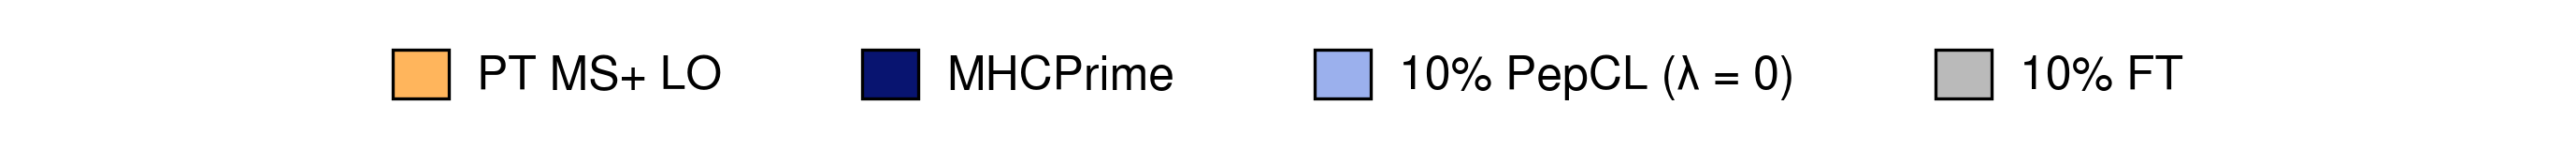

In [ ]:
# legend resized and formatted in illustrator
plot_horizontal_legend(
    legend_dict={
        'PT MS+ LO': "#ffb55c",
        'MHCPrime': '#081470',
        '10% PepCL (λ = 0)': '#9bb0ed',
        '10% FT': '#bababa',
    },
    swatch_size=12,
    text_size=12,
    item_spacing=30,
    swatch_text_gap=6,
    swatch_outline_color='black',
    swatch_outline_width=0.8,
    figsize=None,
    dpi=300,
    default_font='Nimbus Sans',
    save_path=None,
    # save_path=f"{central_figure_dir}/fig3_a_legend",
)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    # ap dfs
    ms_allele_ap_matrix.to_csv(f"{associated_data_dir}/ms_allele_ap_matrix.csv")
    ms_allele_map_matrix_df.to_csv(f"{associated_data_dir}/ms_allele_map_matrix_df.csv")

### Fig. 3b: Per-allele AP difference distributions to the next model

In [ ]:
# get difference of next dataset trained model per allele averaged across 9 updates
base_models=[f"mhcprime_{str(pt_pct)}pct" for pt_pct in split_percentages_dict.keys()]
pepcl_models=[f"mhcprime_{str(pt_pct)}pct_updated_on_10pct_pepcl" for pt_pct in split_percentages_dict.keys()]
ft_models=[f"mhcprime_{str(pt_pct)}pct_updated_on_10pct_ft" for pt_pct in split_percentages_dict.keys()]

ms_allele_ap_matrix_df_perf_diffs_per_allele=compute_score_differences_allele(ms_allele_ap_matrix, base_models, pepcl_models, ft_models)
ms_allele_ap_matrix_df_perf_diffs_per_allele.columns=["rt", "pepcl", "ft"]

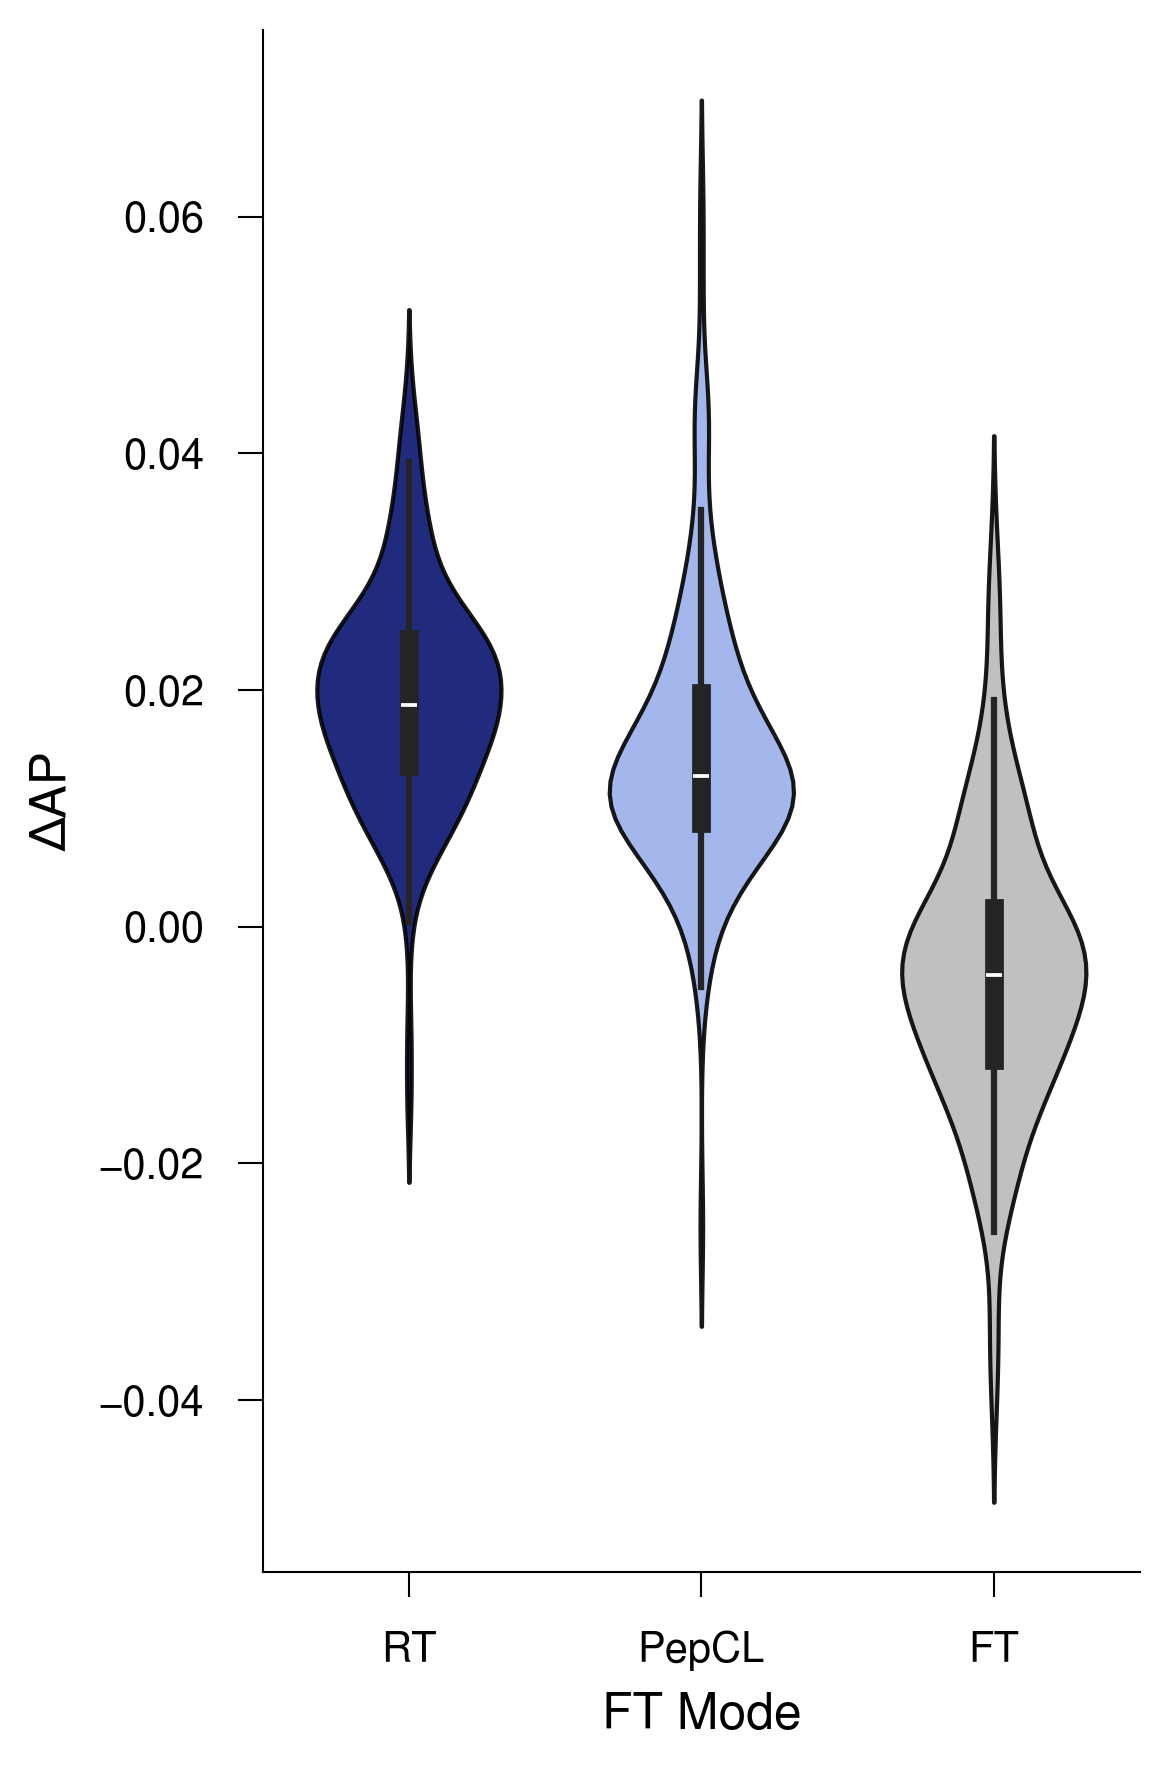

In [ ]:
# plot violin plots
plot_params = {
    'title': '',
    'title_fontsize': 16,
    'title_bold': False,
    'xlabel': 'FT Mode',
    'ylabel': 'ΔAP',
    'xlabel_fontsize': 12,
    'ylabel_fontsize': 12,
    'figsize': (4, 6),
    'dpi': 300,
    'legend_fontsize': 12,
    'legend_cols': 5,
    'legend_handle_size': 0.9,
    'marker_size': 3,
    'axis_linewidth': 0.5,
    'tick_length': 6.0,
    'xlabel_pad': 5.0,
    'ylabel_pad': 5.0,
    'xtick_labelsize': 10,
    'ytick_labelsize': 10
}


model_groups={
    "RT": "rt",
    "PepCL": "pepcl",
    "FT": "ft",
}

colors = {
    'RT': '#081470',
    'PepCL': "#9aafec",
    'FT': "#bababa",
}   

plot_violins_sns(
    df=ms_allele_ap_matrix_df_perf_diffs_per_allele,
    columns=model_groups,
    colors=colors,
    plot_params=plot_params,
    ylim=None,
    grid_alpha=0.0,
    default_font='Nimbus Sans',
    violin_width=0.7,
    violin_outline_color='black',
    violin_outline_width=1.0,
    violin_patch_alpha=0.9,
    violin_inner='box',
    violin_cut=2,
    violin_bw_method='scott',
    hline_y=None,
    hline_label=None,
    hline_color='gray',
    hline_width=1.0,
    hline_style=':',
    hline_text=None,
    hline_text_position='above',
    hline_text_color=None,
    hline_text_fontsize=10,
    hline_text_offset=0.01,
    hline_text_x_offset=0.05,
    hline_in_legend=True,
    reference_hlines=None,
    legend_mode='none',
    legend_loc='lower center',
    legend_bbox=None,
    legend_ncol=None,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig3_b_per_allele_differences_violinplots",
)


In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    ms_allele_ap_matrix_df_perf_diffs_per_allele.to_csv(f"{associated_data_dir}/ms_allele_ap_matrix_df_perf_diffs_per_allele.csv")

### Fig. 3c: Steps per model updating method

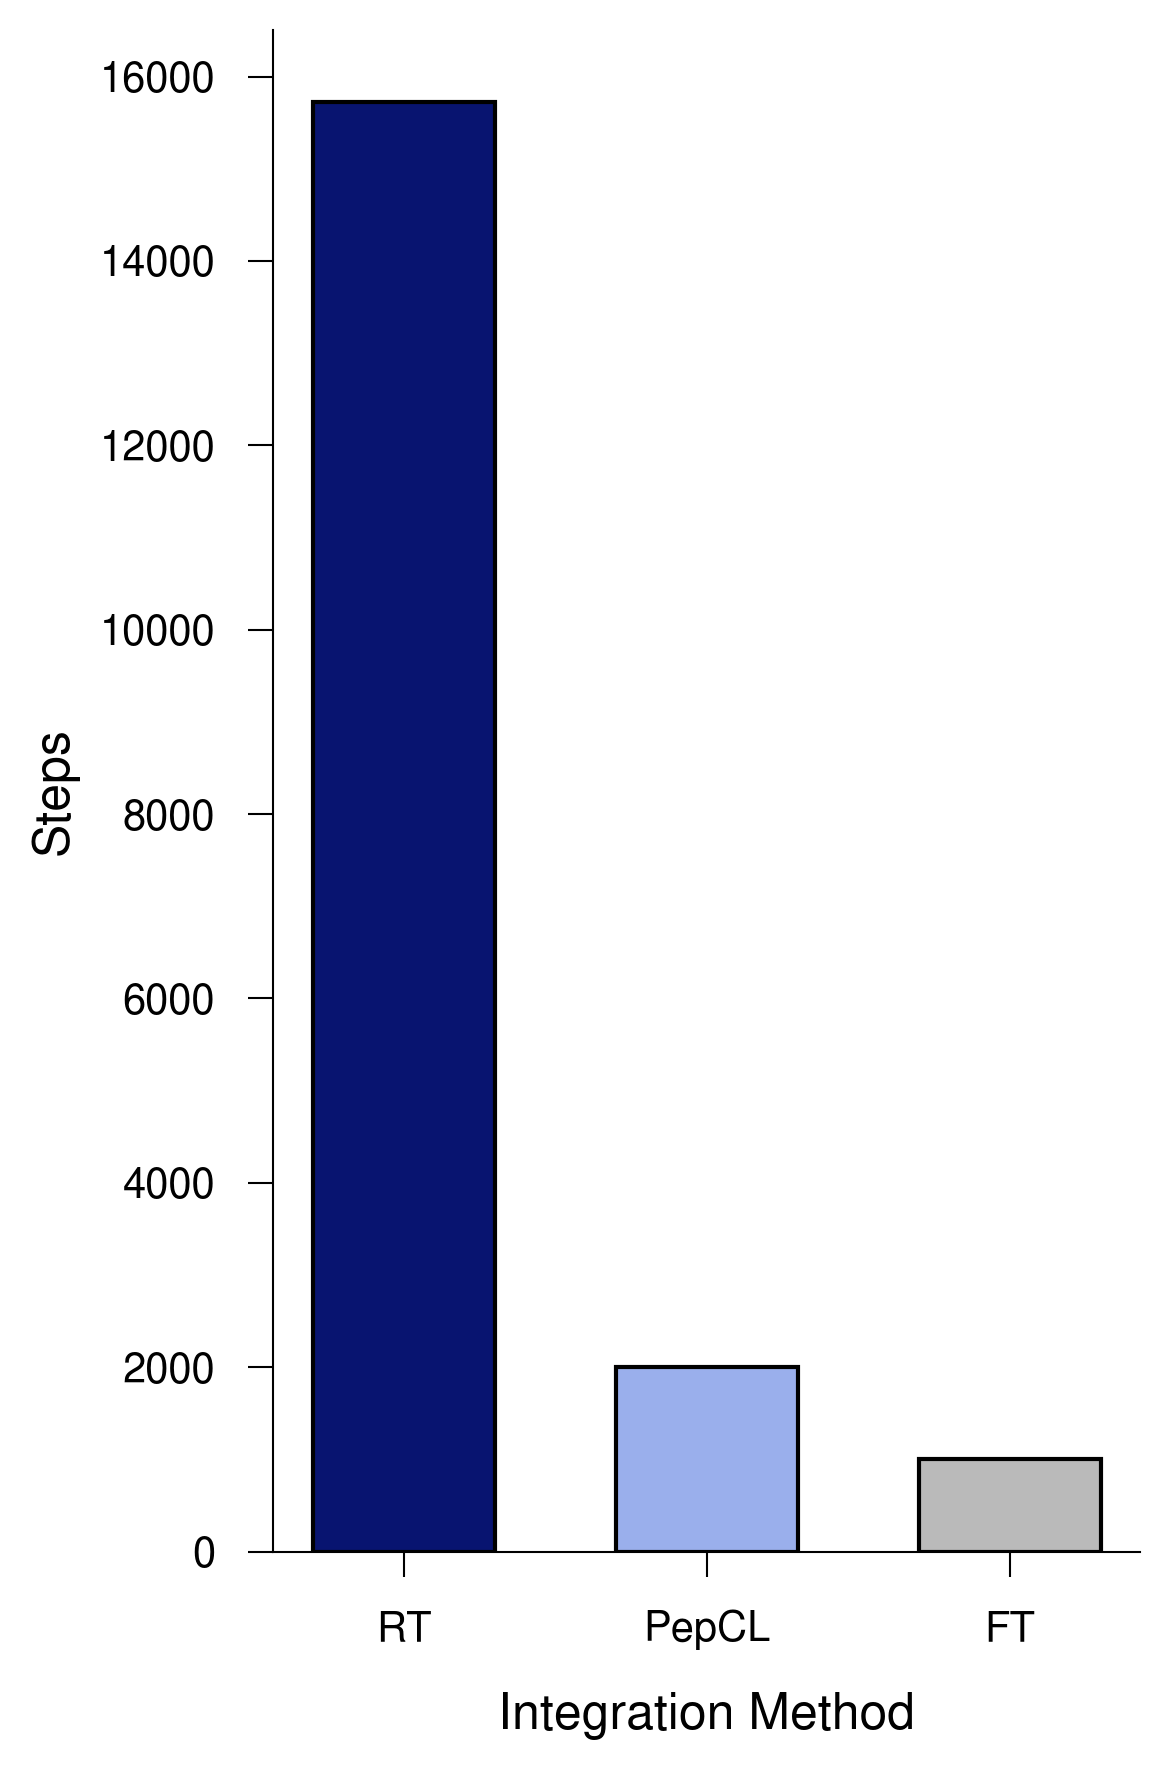

In [ ]:
# for plotting number of steps
data = {'RT': 131*120, 'PepCL': 2000, 'FT': 1000}
colors = {'RT': '#081470', 'PepCL': '#9aafec', 'FT': '#bababa'}

plot_params = {
    'title': '',
    'title_fontsize': 16,
    'title_bold': False,
    'xlabel': 'Integration Method',
    'ylabel': 'Steps',
    'xlabel_fontsize': 12,
    'ylabel_fontsize': 12,
    'figsize': (4, 6),
    'dpi': 300,
    'legend_fontsize': 12,
    'legend_cols': 1,
    'legend_handle_size': 0.9,
    'marker_size': 3,
    'axis_linewidth': 0.5,
    'tick_length': 6.0,
    'xlabel_pad': 10.0,
    'ylabel_pad': 5.0,
    'xtick_labelsize': 10,
    'ytick_labelsize': 10
}

plot_simple_bars(
    data_dict=data,
    colors=colors,
    plot_params=plot_params,
    grid_alpha=0.0,
    default_font='Nimbus Sans',
    bar_width=0.3,
    bar_spacing=0.2,
    bar_outline_color='black',
    bar_outline_width=1.0,
    hline_y=None,
    hline_label=None,
    hline_color='gray',
    hline_width=1.0,
    hline_style=':',
    hline_text=None,
    hline_text_position='above',
    hline_text_color=None,
    hline_text_fontsize=10,
    hline_text_offset=0.01,
    hline_text_x_offset=0.05,
    hline_in_legend=True,
    show_legend=False,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig3_c_rt_pepcl_ft_training_steps_barplot",
)

### Fig. 3d: Cluster-specific updating performance on regular negative background

In [ ]:
%%time
# allele to cluster dict
allele_specific_clusters={
    'A0201': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16], 
    'A0301': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15], 
    'B2705': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13], 
    'B4002': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18], 
    'C0501': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15], 
    'C1202': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
}

multi_allele_ap_matrix_reorganized=pd.DataFrame()

for allele in tqdm(allele_specific_clusters.keys()):

    jt_df=pd.read_csv(f"{DATA_DIR}/Training_Datasets/Processed/MS_Train_Test_Sets/Cluster_Specific_Analysis/{allele}/cluster_specific_test_set.csv", index_col=0)

    score_cols=[f"mhcprime_holdout_{allele.lower()}_{str(lid)}" for lid in allele_specific_clusters[allele]]
    score_cols+=[f"mhcprime_holdout_{allele.lower()}_full", f"mhcprime_holdout_{allele.lower()}_null"]

    score_cols+=[f"model_ft_{allele.lower()}_{str(lid)}" for lid in allele_specific_clusters[allele]]
    score_cols+=[f"model_pepcl_{allele.lower()}_{str(lid)}_lambda_1eN4" for lid in allele_specific_clusters[allele]]

    # print(len(score_cols), score_cols)

    allele_ap_matrix=compute_ap_matrix_optimized(jt_df, score_cols, label_col='label', allele_col='louvain_id')

    allele_ap_matrix_reorganized=reorganize_performance_df(allele_ap_matrix, allele)

    allele_ap_matrix_reorganized["allele"]=allele

    multi_allele_ap_matrix_reorganized=pd.concat([multi_allele_ap_matrix_reorganized, allele_ap_matrix_reorganized])

100%|██████████| 6/6 [00:12<00:00,  2.02s/it]

CPU times: user 11.5 s, sys: 651 ms, total: 12.2 s
Wall time: 12.1 s


In [ ]:
# get pvals
multi_allele_ap_matrix_reorganized_cluster=multi_allele_ap_matrix_reorganized[[c for c in multi_allele_ap_matrix_reorganized.columns if c.endswith('_cluster')]].copy()

display(compute_pairwise_pvalues_general(multi_allele_ap_matrix_reorganized_cluster))
display(pval_to_stars(compute_pairwise_pvalues_general(multi_allele_ap_matrix_reorganized_cluster)))

,mhcprime_cluster,model_ft_cluster,model_pepcl_cluster,full_cluster,null_cluster
mhcprime_cluster,1.000000e+00,1.218119e-17,1.218119e-17,3.282150e-17,9.329874e-03
model_ft_cluster,1.218119e-17,1.000000e+00,1.218119e-17,1.218119e-17,1.218119e-17
model_pepcl_cluster,1.218119e-17,1.218119e-17,1.000000e+00,1.585547e-14,1.296464e-17
full_cluster,3.282150e-17,1.218119e-17,1.585547e-14,1.000000e+00,2.223502e-16
null_cluster,9.329874e-03,1.218119e-17,1.296464e-17,2.223502e-16,1.000000e+00


,mhcprime_cluster,model_ft_cluster,model_pepcl_cluster,full_cluster,null_cluster
mhcprime_cluster,ns,****,****,****,**
model_ft_cluster,****,ns,****,****,****
model_pepcl_cluster,****,****,ns,****,****
full_cluster,****,****,****,ns,****
null_cluster,**,****,****,****,ns


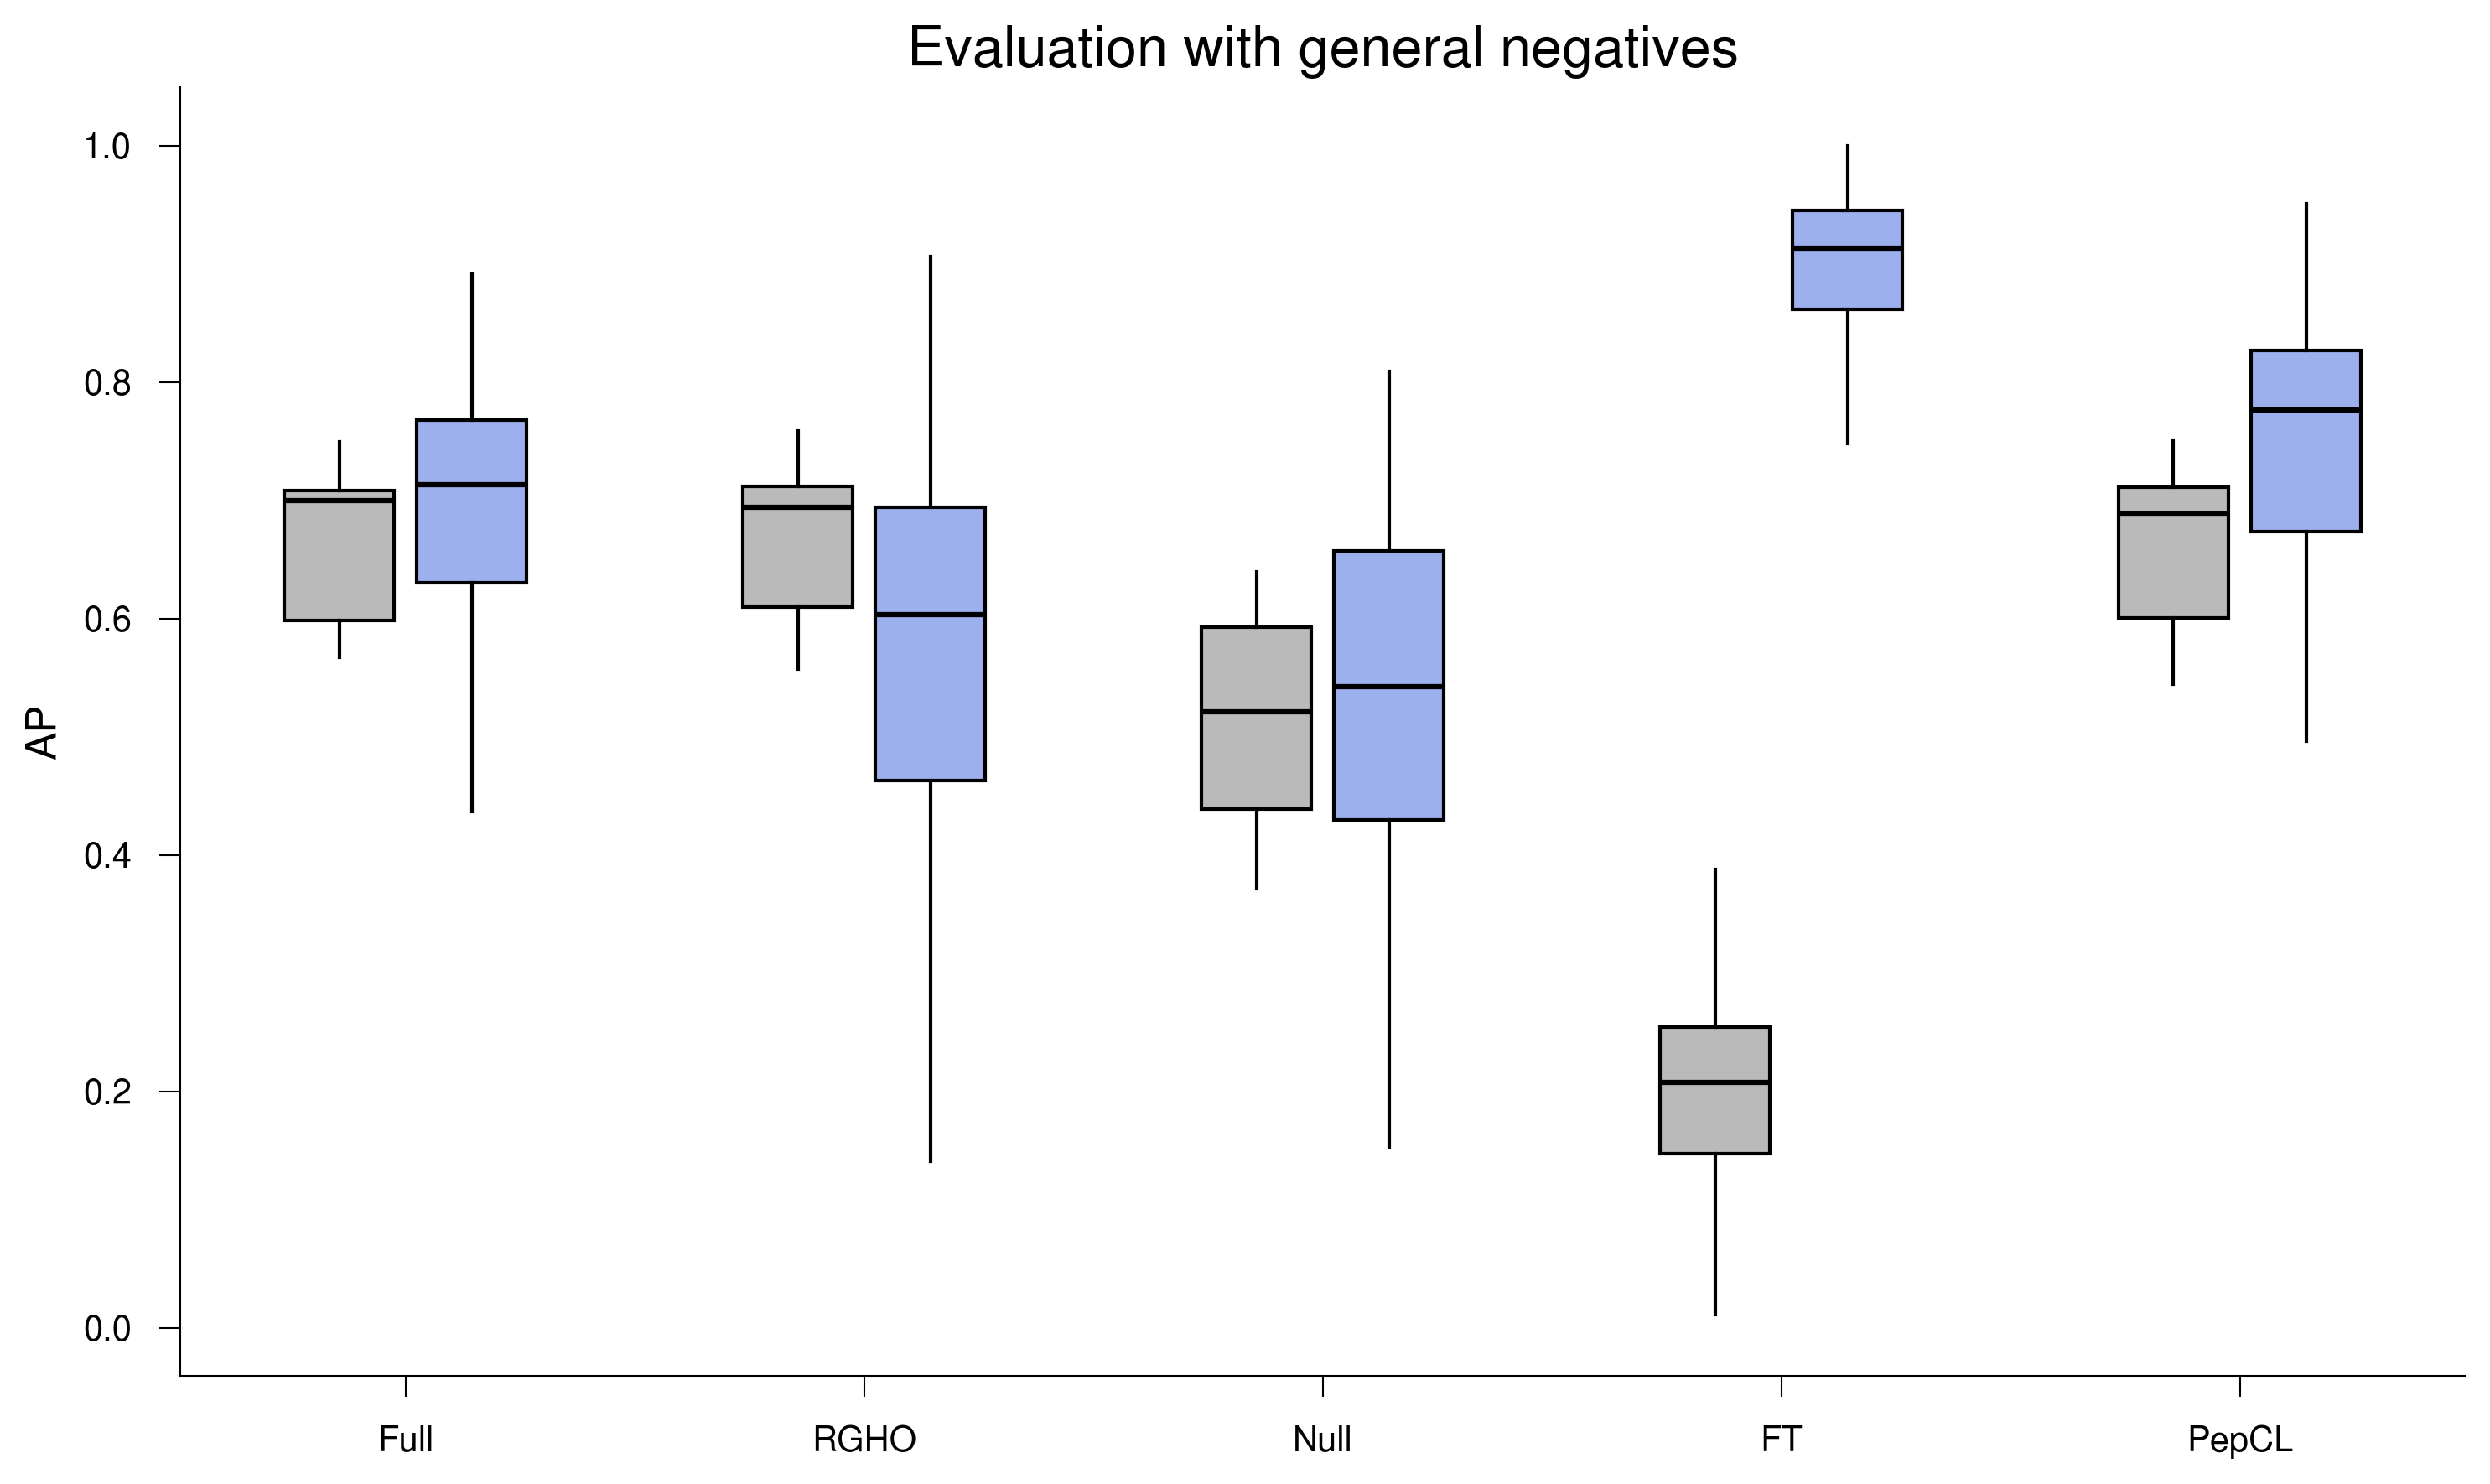

In [ ]:
# plot grouped boxplots
boxplot_groups={
    "Full": [(multi_allele_ap_matrix_reorganized, "full_prior"), (multi_allele_ap_matrix_reorganized, "full_cluster")],
    "RGHO": [(multi_allele_ap_matrix_reorganized, "mhcprime_prior"), (multi_allele_ap_matrix_reorganized, "mhcprime_cluster")],
    "Null": [(multi_allele_ap_matrix_reorganized, "null_prior"), (multi_allele_ap_matrix_reorganized, "null_cluster")],
    "FT": [(multi_allele_ap_matrix_reorganized, "model_ft_prior"), (multi_allele_ap_matrix_reorganized, "model_ft_cluster")],
    "PepCL": [(multi_allele_ap_matrix_reorganized, "model_pepcl_prior"), (multi_allele_ap_matrix_reorganized, "model_pepcl_cluster")],

}

target_cluster_color="#9BB0ED"
prior_color="#bababa"

colors={
    "full_prior": prior_color,
    "mhcprime_prior": prior_color,
    "null_prior": prior_color,
    "model_ft_prior": prior_color,
    "model_pepcl_prior": prior_color,

    "full_cluster": target_cluster_color,
    "mhcprime_cluster": target_cluster_color,
    "null_cluster": target_cluster_color,
    "model_ft_cluster": target_cluster_color,
    "model_pepcl_cluster": target_cluster_color,
}

plot_params = {
    'title': 'Evaluation with general negatives',
    'title_fontsize': 16,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'AP',
    'xlabel_fontsize': 12,
    'ylabel_fontsize': 12,
    'figsize': (10, 6),
    'dpi': 300,
    'legend_fontsize': 12,
    'legend_cols': 5,
    'legend_handle_size': 0.9,
    'marker_size': 3,
    'axis_linewidth': 0.5,
    'tick_length': 6.0,
    'xlabel_pad': 5.0,
    'ylabel_pad': 5.0,
    'xtick_labelsize': 10,
    'ytick_labelsize': 10

}

pval_df=plot_grouped_boxplots(
    boxplot_groups,
    colors=colors,
    legend=None,
    plot_params=plot_params,
    ylim=None,
    grid_alpha=0.0,
    default_font='Nimbus Sans',
    box_width=0.6,
    group_spacing=1.0,
    box_spacing=0.05,
    box_outline_color='black',
    box_outline_width=1.0,
    box_flier_marker='o',
    box_flier_size=0,
    box_flier_color="#2B2B2B",
    box_flier_alpha=0.6,
    box_flier_edge_width=0,
    box_median_color='black',
    box_median_width=1.5,
    box_whisker_style='-',
    box_whisker_width=1.0,
    box_notch=False,
    box_patch_alpha=1.0,
    hline_y=None,
    hline_label=None,
    hline_color='gray',
    hline_width=1.0,
    hline_style=':',
    hline_text=None,
    hline_text_position='above',
    hline_text_color=None,
    hline_text_fontsize=10,
    hline_text_offset=0.01,
    hline_text_x_offset=0.05,
    hline_in_legend=True,
    reference_hlines=None,
    legend_mode='integrated',
    legend_loc='lower center',
    legend_bbox=None,
    legend_ncol=None,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig3_d_cluster_specific_updating_evaluation_with_regular_negatives",
    compute_pvalues=True,
    pvalue_test='wilcoxon',
    cluster_col='louvain_id',

)

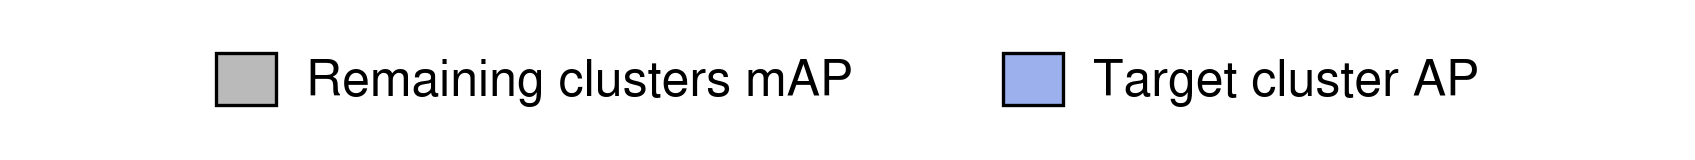

In [ ]:
# legend resized and formatted in illustrator
plot_horizontal_legend(
    legend_dict={
        'Remaining clusters mAP': '#bababa',
        'Target cluster AP': '#9bb0ed',
    },
    swatch_size=12,
    text_size=12,
    item_spacing=30,
    swatch_text_gap=6,
    swatch_outline_color='black',
    swatch_outline_width=0.8,
    figsize=None,
    dpi=300,
    default_font='Nimbus Sans',
    save_path=None,
    # save_path=f"{central_figure_dir}/fig3_d_legend",
)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    multi_allele_ap_matrix_reorganized.to_csv(f"{associated_data_dir}/cluster_specific_updating_regular_negatives_evaluation_df.csv")

### Fig. 3e: Cluster-specific updating performance on hard negative background

In [ ]:
%%time
# allele to cluster dict
allele_specific_clusters={
    'A0201': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16], 
    'A0301': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15], 
    'B2705': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13], 
    'B4002': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18], 
    'C0501': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15], 
    'C1202': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
}

multi_allele_ap_matrix_reorganized=pd.DataFrame()

for allele in tqdm(allele_specific_clusters.keys()):

    jt_df=pd.read_csv(f"{DATA_DIR}/Training_Datasets/Processed/MS_Train_Test_Sets/Cluster_Specific_Analysis/{allele}/cluster_specific_test_set_hard_negatives.csv", index_col=0)

    score_cols=[f"mhcprime_holdout_{allele.lower()}_{str(lid)}" for lid in allele_specific_clusters[allele]]
    score_cols+=[f"mhcprime_holdout_{allele.lower()}_full", f"mhcprime_holdout_{allele.lower()}_null"]

    score_cols+=[f"model_ft_{allele.lower()}_{str(lid)}" for lid in allele_specific_clusters[allele]]
    score_cols+=[f"model_pepcl_{allele.lower()}_{str(lid)}_lambda_1eN4" for lid in allele_specific_clusters[allele]]

    # print(len(score_cols), score_cols)

    allele_ap_matrix=compute_ap_matrix_optimized(jt_df, score_cols, label_col='label', allele_col='louvain_id')

    allele_ap_matrix_reorganized=reorganize_performance_df(allele_ap_matrix, allele)

    allele_ap_matrix_reorganized["allele"]=allele

    multi_allele_ap_matrix_reorganized=pd.concat([multi_allele_ap_matrix_reorganized, allele_ap_matrix_reorganized])

100%|██████████| 6/6 [00:13<00:00,  2.18s/it]

CPU times: user 12.8 s, sys: 367 ms, total: 13.2 s
Wall time: 13.1 s


In [ ]:
# get pvals
multi_allele_ap_matrix_reorganized_cluster=multi_allele_ap_matrix_reorganized[[c for c in multi_allele_ap_matrix_reorganized.columns if c.endswith('_cluster')]].copy()

display(compute_pairwise_pvalues_general(multi_allele_ap_matrix_reorganized_cluster))
display(pval_to_stars(compute_pairwise_pvalues_general(multi_allele_ap_matrix_reorganized_cluster)))

,mhcprime_cluster,model_ft_cluster,model_pepcl_cluster,full_cluster,null_cluster
mhcprime_cluster,1.000000e+00,2.543489e-07,3.317763e-15,6.432324e-08,8.705748e-16
model_ft_cluster,2.543489e-07,1.000000e+00,2.291124e-16,9.790318e-16,4.085027e-11
model_pepcl_cluster,3.317763e-15,2.291124e-16,1.000000e+00,5.113882e-01,1.337481e-17
full_cluster,6.432324e-08,9.790318e-16,5.113882e-01,1.000000e+00,1.218119e-17
null_cluster,8.705748e-16,4.085027e-11,1.337481e-17,1.218119e-17,1.000000e+00


,mhcprime_cluster,model_ft_cluster,model_pepcl_cluster,full_cluster,null_cluster
mhcprime_cluster,ns,****,****,****,****
model_ft_cluster,****,ns,****,****,****
model_pepcl_cluster,****,****,ns,ns,****
full_cluster,****,****,ns,ns,****
null_cluster,****,****,****,****,ns


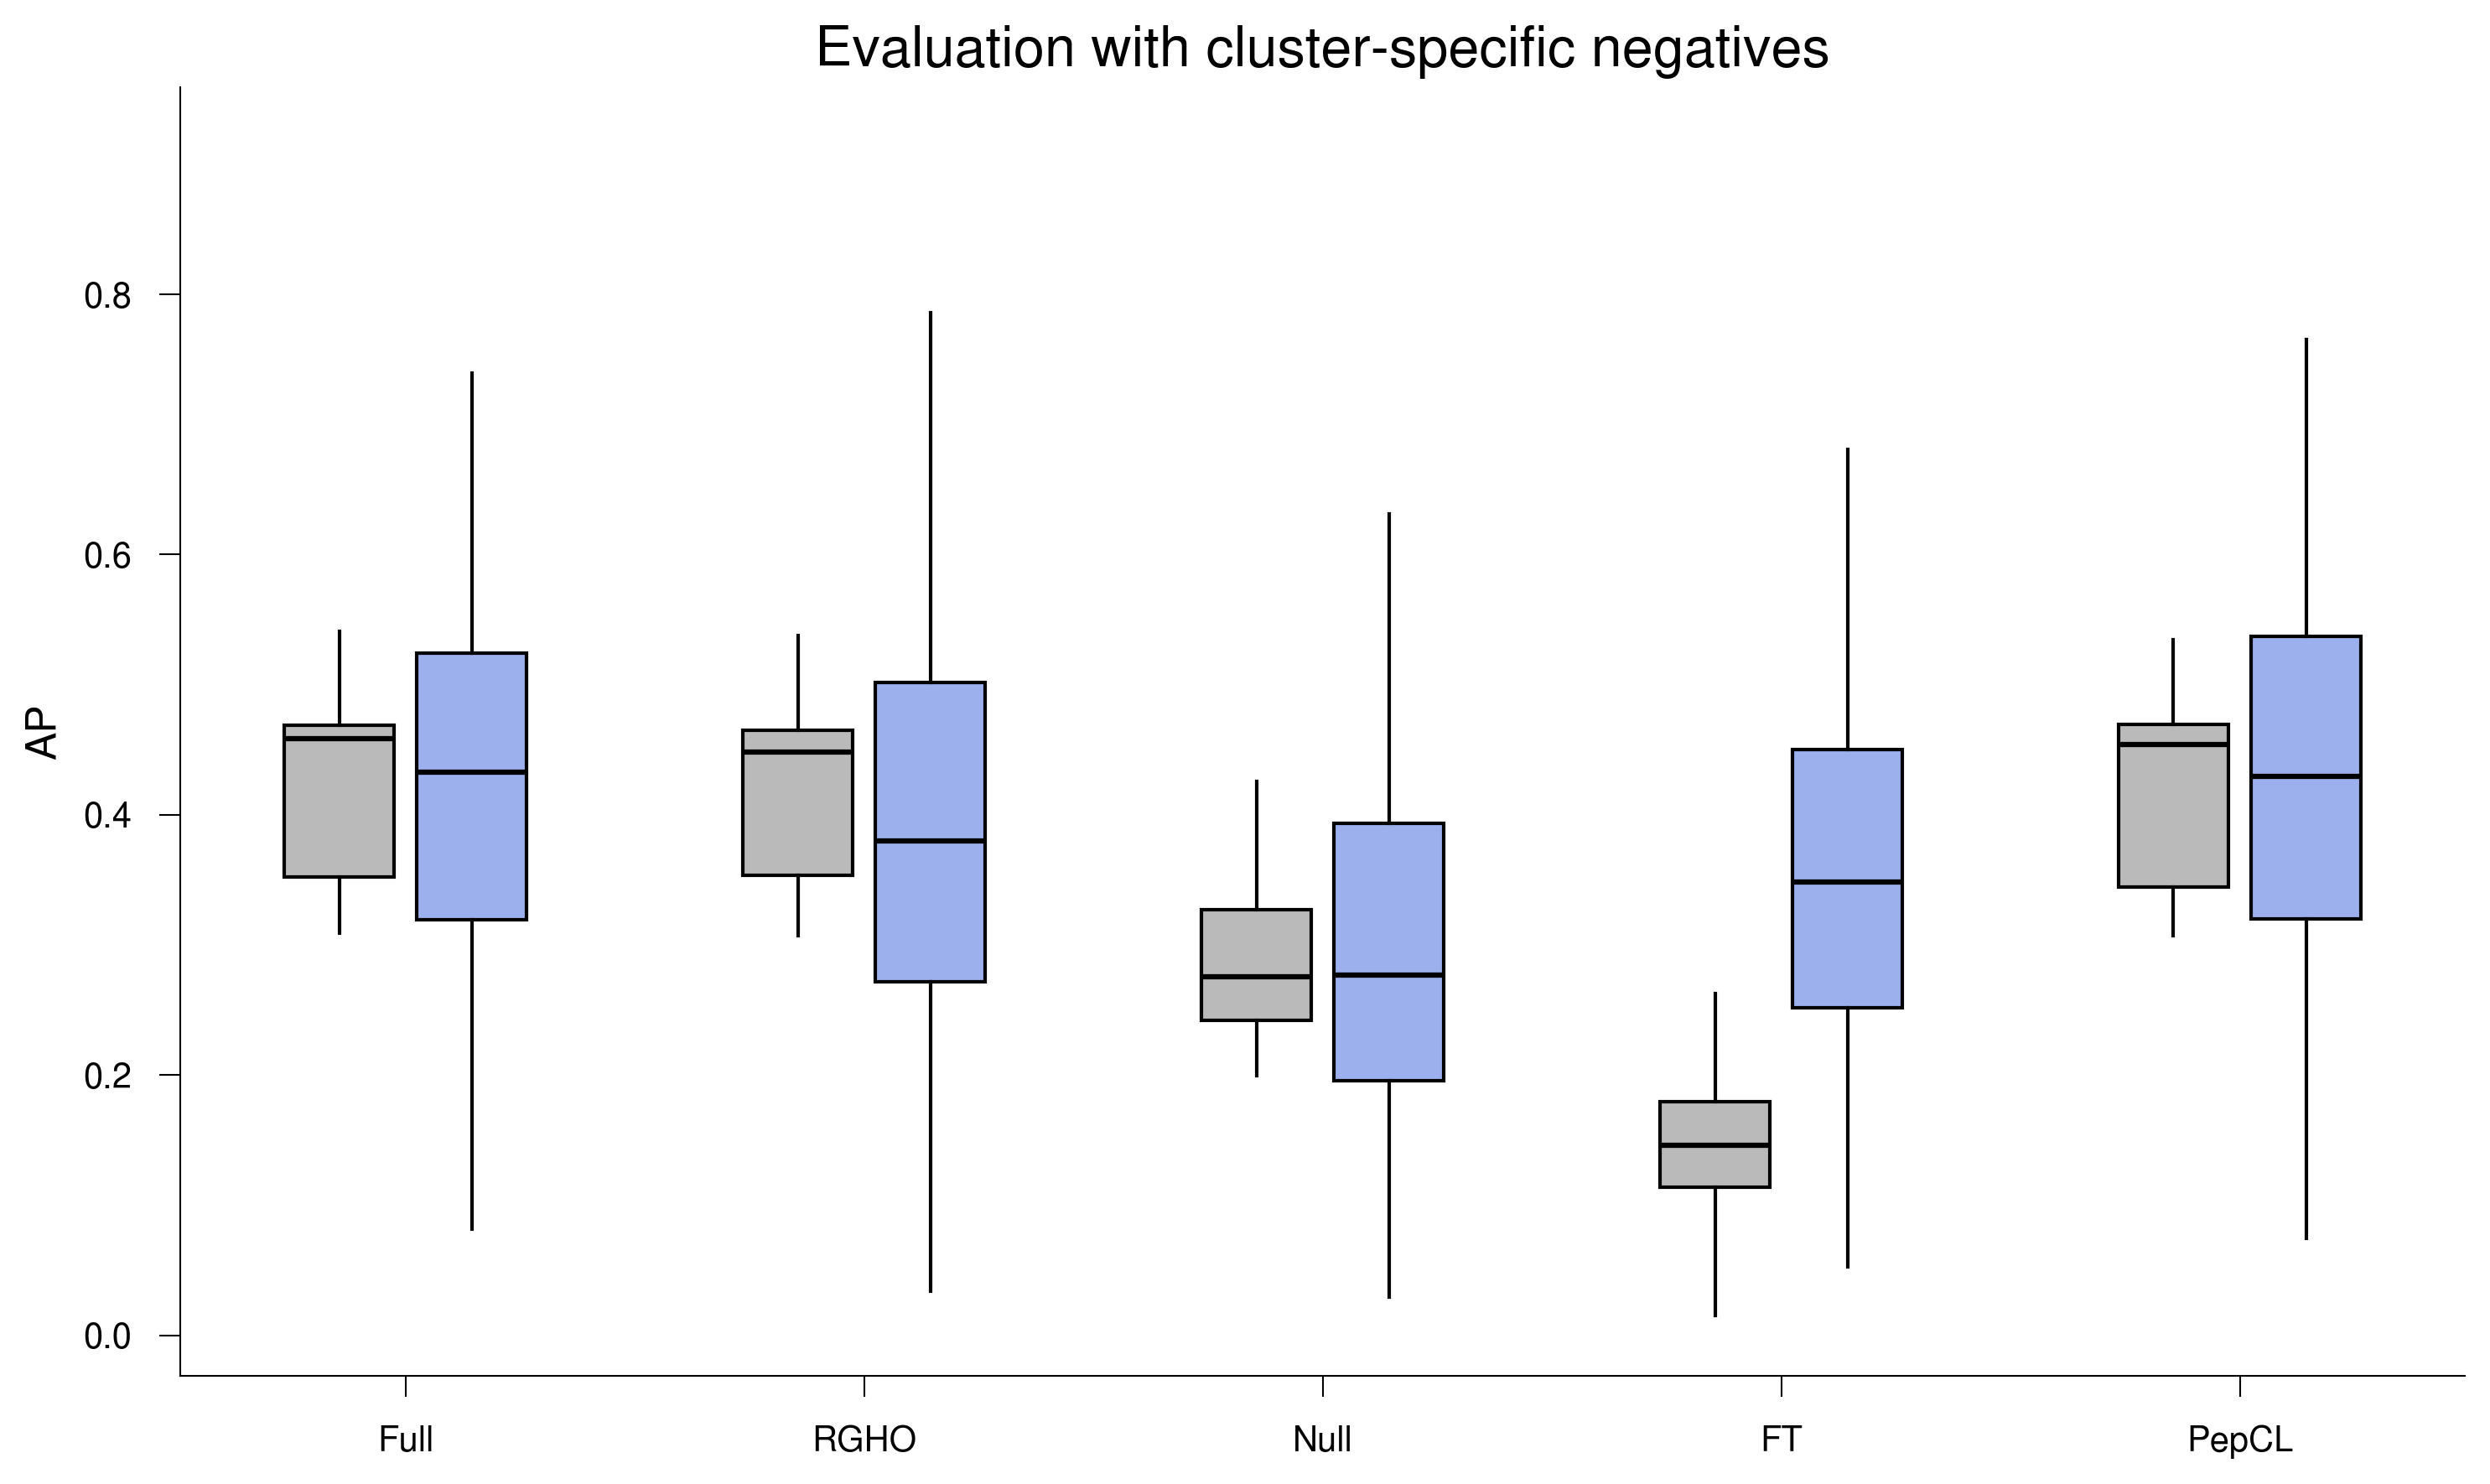

In [ ]:
# plot grouped boxplots
boxplot_groups={
    "Full": [(multi_allele_ap_matrix_reorganized, "full_prior"), (multi_allele_ap_matrix_reorganized, "full_cluster")],
    "RGHO": [(multi_allele_ap_matrix_reorganized, "mhcprime_prior"), (multi_allele_ap_matrix_reorganized, "mhcprime_cluster")],
    "Null": [(multi_allele_ap_matrix_reorganized, "null_prior"), (multi_allele_ap_matrix_reorganized, "null_cluster")],
    "FT": [(multi_allele_ap_matrix_reorganized, "model_ft_prior"), (multi_allele_ap_matrix_reorganized, "model_ft_cluster")],
    "PepCL": [(multi_allele_ap_matrix_reorganized, "model_pepcl_prior"), (multi_allele_ap_matrix_reorganized, "model_pepcl_cluster")],

}

target_cluster_color="#9BB0ED"
prior_color="#bababa"

colors={
    "full_prior": prior_color,
    "mhcprime_prior": prior_color,
    "null_prior": prior_color,
    "model_ft_prior": prior_color,
    "model_pepcl_prior": prior_color,

    "full_cluster": target_cluster_color,
    "mhcprime_cluster": target_cluster_color,
    "null_cluster": target_cluster_color,
    "model_ft_cluster": target_cluster_color,
    "model_pepcl_cluster": target_cluster_color,
}

plot_params = {
    'title': 'Evaluation with cluster-specific negatives',
    'title_fontsize': 16,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'AP',
    'xlabel_fontsize': 12,
    'ylabel_fontsize': 12,
    'figsize': (10, 6),
    'dpi': 300,
    'legend_fontsize': 12,
    'legend_cols': 5,
    'legend_handle_size': 0.9,
    'marker_size': 3,
    'axis_linewidth': 0.5,
    'tick_length': 6.0,
    'xlabel_pad': 5.0,
    'ylabel_pad': 5.0,
    'xtick_labelsize': 10,
    'ytick_labelsize': 10

}

pval_df=plot_grouped_boxplots(
    boxplot_groups,
    colors=colors,
    legend=None,
    plot_params=plot_params,
    ylim=None,
    grid_alpha=0.0,
    default_font='Nimbus Sans',
    box_width=0.6,
    group_spacing=1.0,
    box_spacing=0.05,
    box_outline_color='black',
    box_outline_width=1.0,
    box_flier_marker='o',
    box_flier_size=0,
    box_flier_color="#2B2B2B",
    box_flier_alpha=0.6,
    box_flier_edge_width=0,
    box_median_color='black',
    box_median_width=1.5,
    box_whisker_style='-',
    box_whisker_width=1.0,
    box_notch=False,
    box_patch_alpha=1.0,
    hline_y=None,
    hline_label=None,
    hline_color='gray',
    hline_width=1.0,
    hline_style=':',
    hline_text=None,
    hline_text_position='above',
    hline_text_color=None,
    hline_text_fontsize=10,
    hline_text_offset=0.01,
    hline_text_x_offset=0.05,
    hline_in_legend=True,
    reference_hlines=None,
    legend_mode='integrated',
    legend_loc='lower center',
    legend_bbox=None,
    legend_ncol=None,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig3_e_cluster_specific_updating_evaluation_with_hard_negatives",
    compute_pvalues=True,
    pvalue_test='wilcoxon',
    cluster_col='louvain_id',

)

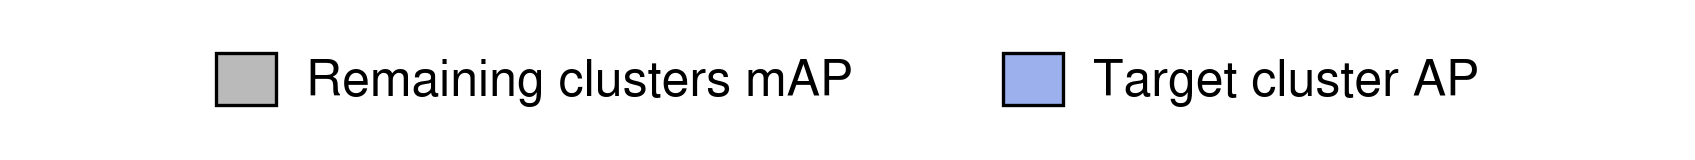

In [ ]:
# legend resized and formatted in illustrator
plot_horizontal_legend(
    legend_dict={
        'Remaining clusters mAP': '#bababa',
        'Target cluster AP': '#9bb0ed',
    },
    swatch_size=12,
    text_size=12,
    item_spacing=30,
    swatch_text_gap=6,
    swatch_outline_color='black',
    swatch_outline_width=0.8,
    figsize=None,
    dpi=300,
    default_font='Nimbus Sans',
    save_path=None,
    # save_path=f"{central_figure_dir}/fig3_e_legend",
)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    multi_allele_ap_matrix_reorganized.to_csv(f"{associated_data_dir}/cluster_specific_updating_hard_negatives_evaluation_df.csv")

### Fig. 3f: Cluster-specific distance to performance drop scatterplot

In [ ]:
%%time
# get distance and delta map dataframe
allele_specific_clusters={
    'A0201': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16], 
    'A0301': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15], 
    'B2705': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13], 
    'B4002': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18], 
    'C0501': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15], 
    'C1202': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
}

lid_holdout_mean_ap_merged_df_per_allele={}

for ta, clusters in allele_specific_clusters.items():
    score_cols_to_select=[f"mhcprime_holdout_{ta.lower()}_{str(lid_name)}" for lid_name in allele_specific_clusters[ta]]

    jt_df=pd.read_csv(f"{DATA_DIR}/Training_Datasets/Processed/MS_Train_Test_Sets/Cluster_Specific_Analysis/{ta}/cluster_specific_test_set.csv", index_col=0)

    allele_ap_matrix=compute_ap_matrix_optimized(jt_df[score_cols_to_select+["label", "louvain_id"]], score_cols_to_select, label_col='label', allele_col='louvain_id')

    lid_holdout_mean_ap_base_df=extract_holdout_mean_ap(allele_ap_matrix, score_col_name='score_col', cluster_col_name='louvain_id', mean_ap_col_name='mean_ap_holdout_base')

    # get the holdout mean ap 
    cluster_to_col={lid: f"model_ft_{ta.lower()}_{str(lid)}" for lid in allele_specific_clusters[ta]}

    allele_ap_matrix=compute_ap_matrix_optimized(jt_df, jt_df.select_dtypes(include=[np.number]).columns.tolist(), label_col='label', allele_col='louvain_id')

    lid_holdout_mean_ap_ft_df=extract_holdout_mean_ap_dict(allele_ap_matrix, cluster_to_col, score_col_name='score_col',cluster_col_name='louvain_id', mean_ap_col_name='mean_ap_model_ft')

    allele_train_pos_df=pd.read_csv(f"{DATA_DIR}/Training_Datasets/Processed/MS_Train_Test_Sets/Cluster_Specific_Analysis/{ta}/allele_train_pos_df.csv", index_col=0)

    js_mat_louv_allele_test=compute_louvain_js_matrix(
        df=allele_train_pos_df,
        peptide_col = "peptide",
        cluster_col = "louvain_id",
        length = 9,
        js_min_cluster_count = 50,
        js_alpha = 0.5,
        js_agg = "mean",
        device="cuda",
        verbose = True,
    )

    # get nearest neighbor; make sure it is allele-specific
    js_nn_df_allele=js_mean_of_nearest_neighbors_multi_w_to_rest(
        js_mat=js_mat_louv_allele_test,
        neighbors = [1,2,3,4,5,6,7,8,9,10,11,12],
        cluster_col = "louvain_id",
        out_prefix = "js_mean_nn",
        ignore_ids = None,
        include_self = False,
        to_rest=True,
    )

    # merge three above dfs and compute delta ap
    lid_holdout_mean_ap_merged_df=pd.merge(lid_holdout_mean_ap_base_df, lid_holdout_mean_ap_ft_df, on='louvain_id')

    lid_holdout_mean_ap_merged_df=pd.merge(lid_holdout_mean_ap_merged_df, js_nn_df_allele, on='louvain_id')

    for col in tqdm(lid_holdout_mean_ap_merged_df.columns):
        if "js_mean_nn" in col or "dist_to_rest" in col:
            lid_holdout_mean_ap_merged_df=minmax_normalize_js(
                df=lid_holdout_mean_ap_merged_df,
                js_col=col,
                out_col=f"{col}_norm",
                clip = True,
            )

    lid_holdout_mean_ap_merged_df["ap_delta"]=lid_holdout_mean_ap_merged_df["mean_ap_model_ft"]-lid_holdout_mean_ap_merged_df["mean_ap_holdout_base"]

    lid_holdout_mean_ap_merged_df["allele"]=ta
    lid_holdout_mean_ap_merged_df["HLA"]=ta[0]

    lid_holdout_mean_ap_merged_df_per_allele[ta]=lid_holdout_mean_ap_merged_df

100%|██████████| 17/17 [00:02<00:00,  6.11it/s]


[js] Computing PWM-JS matrix for 17 clusters (min_cluster_count=50, alpha=0.5, agg=mean)


100%|██████████| 16/16 [00:00<00:00, 17.24it/s]


[js] Computing PWM-JS matrix for 17 clusters (min_cluster_count=50, alpha=0.5, agg=mean)


100%|██████████| 14/14 [00:01<00:00, 11.94it/s]


...

[js] Computing PWM-JS matrix for 16 clusters (min_cluster_count=50, alpha=0.5, agg=mean)


100%|██████████| 15/15 [00:00<00:00, 20.36it/s]


[js] Computing PWM-JS matrix for 16 clusters (min_cluster_count=50, alpha=0.5, agg=mean)


100%|██████████| 31/31 [00:00<00:00, 2666.93it/s]

CPU times: user 24.9 s, sys: 1.25 s, total: 26.2 s
Wall time: 26.1 s


In [ ]:
# agg dfs
lid_holdout_mean_ap_merged_df_multi=pd.concat([lid_holdout_mean_ap_merged_df_per_allele["A0201"], lid_holdout_mean_ap_merged_df_per_allele["A0301"],lid_holdout_mean_ap_merged_df_per_allele["B2705"], lid_holdout_mean_ap_merged_df_per_allele["B4002"], lid_holdout_mean_ap_merged_df_per_allele["C0501"],lid_holdout_mean_ap_merged_df_per_allele["C1202"]])

lid_holdout_mean_ap_merged_df_multi.reset_index(inplace=True, drop=True)
print(lid_holdout_mean_ap_merged_df_multi.shape)

(97, 47)


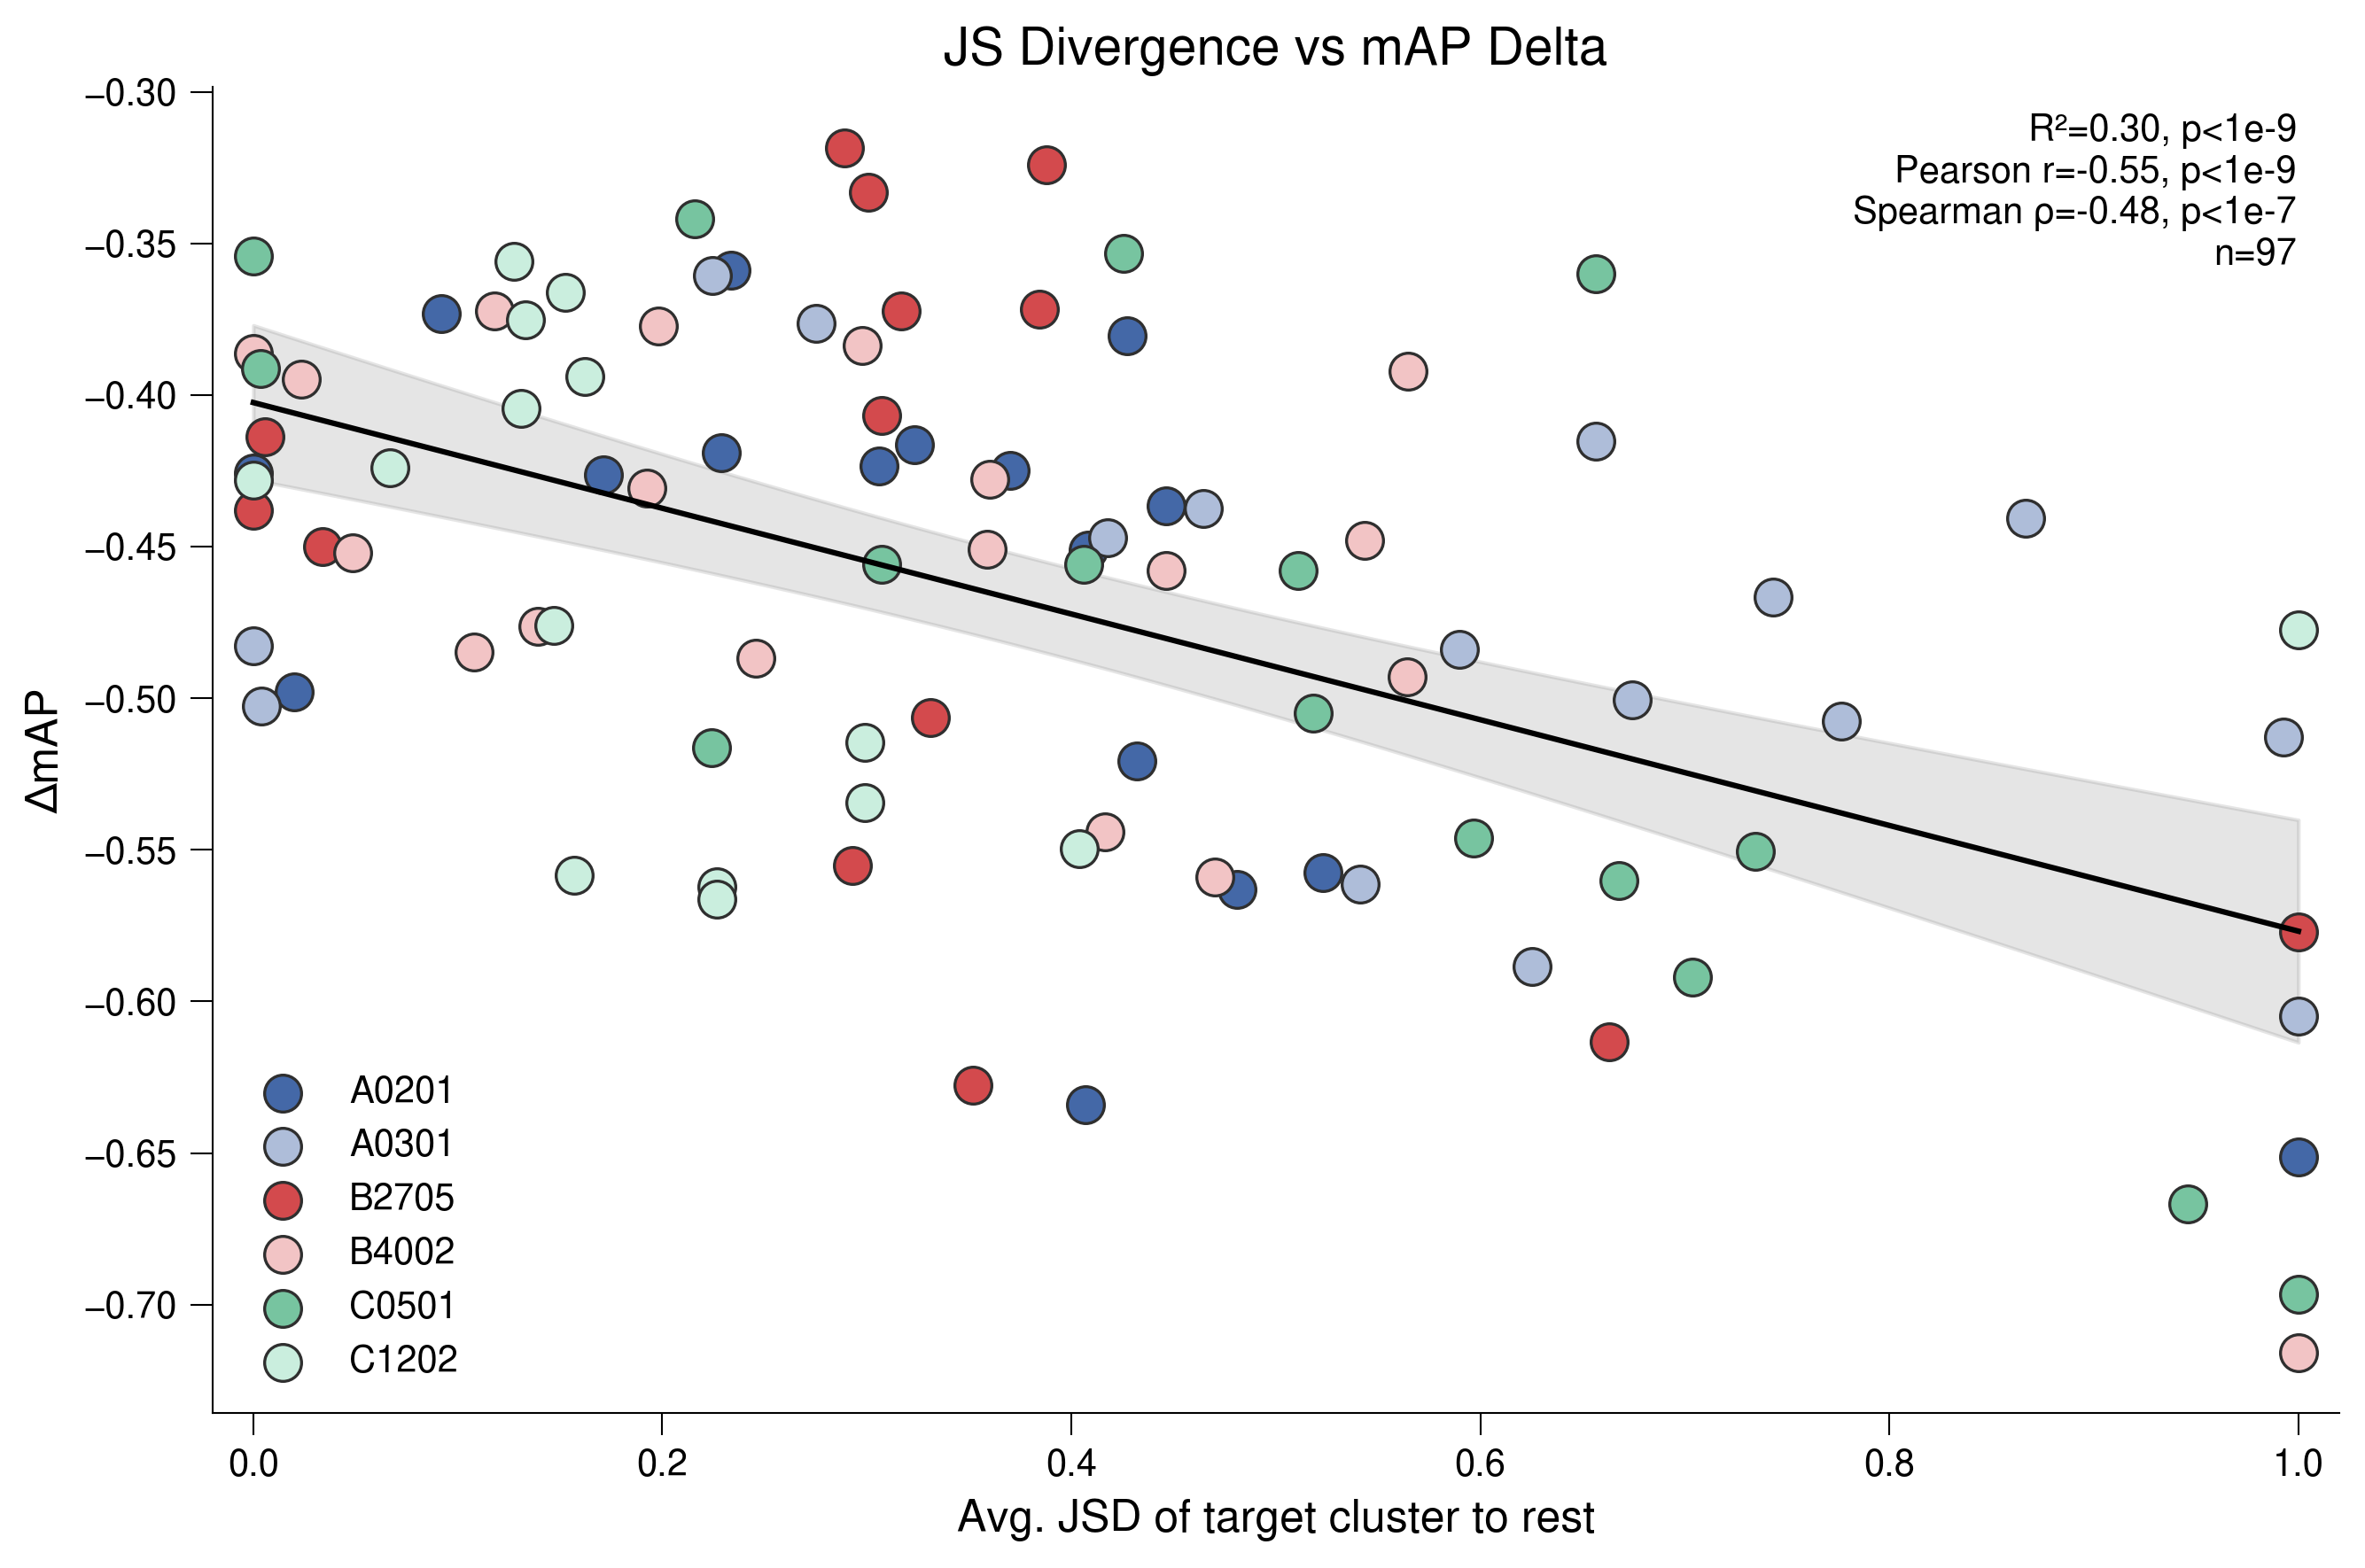

In [ ]:
"""
plot regression
"""
ax, regression_stats=plot_scatter_regression(
    df=lid_holdout_mean_ap_merged_df_multi,
    x_col=f"dist_to_rest_norm",
    y_col='ap_delta',
    scatter_alpha=1.0,
    # scatter_s=28.0,
    # scatter_s=40.0,
    # scatter_s=60.0,
    # scatter_s=80.0,
    scatter_s=100.0,
    scatter_color='#1f77b4',
    scatter_marker='o',
    scatter_edge_color="#2f2f2f",
    scatter_edge_width=0.8,
    hue_col='allele',
    hue_colors={
        # set 5
        'A0201': "#4468A7", 
        'A0301': "#AEBDD9", 
        'B2705': "#D34A4D",
        'B4002': "#F2C4C5",
        'C0501': "#77C4A0",
        'C1202': "#CAEEDE",
    },
    hue_order=['A0201', 'A0301', 'B2705', 'B4002', 'C0501', 'C1202'],

    show_regression=True,
    regression_color='black',
    regression_width=1.5,
    regression_style='-',
    regression_alpha=1.0,
    show_ci=True,
    ci_level=0.95,
    ci_color='gray',
    ci_alpha=0.2,
    show_spearman=True,
    spearman_fontsize=10,
    spearman_loc='upper right',
    spearman_bbox_alpha=0.8,
    spearman_bbox_color='white',
    figsize=(9, 6),
    dpi=300,
    default_font='Nimbus Sans',
    remove_top_right_spines=True,
    spine_width=0.5,
    tick_length=6.0,
    tick_width=0.5,
    tick_direction='out',
    title='JS Divergence vs mAP Delta',
    title_fontsize=14,
    title_bold=False,
    xlabel='Avg. JSD of target cluster to rest',
    ylabel='ΔmAP',
    xlabel_fontsize=12,
    ylabel_fontsize=12,
    xtick_labelsize=10,
    ytick_labelsize=10,
    xlabel_pad=4.0,
    ylabel_pad=4.0,
    legend_fontsize=10,
    legend_loc='best',
    legend_frameon=False,
    xlim=None,
    ylim=None,
    grid_alpha=0.0,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig3_f_cluster_jsd_vs_delta_map_scatterplot", 
    show=True,
    output_stats_df=True,
)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    lid_holdout_mean_ap_merged_df_multi.to_csv(f"{associated_data_dir}/cluster_distance_vs_delta_map_results.csv")
    regression_stats.to_csv(f"{associated_data_dir}/cluster_distance_vs_delta_map_regression_stats.csv")

### Fig. 3g: Lambda controllability test on A*02:01 cluster 1

In [ ]:
# get associated data
target_allele="A0201"

joint_ext_test_df=pd.read_csv(f"{DATA_DIR}/Training_Datasets/Processed/MS_Train_Test_Sets/Cluster_Specific_Analysis/{target_allele}/cluster_specific_test_set.csv", index_col=0)

allele_train_pos_df=pd.read_csv(f"{DATA_DIR}/Training_Datasets/Processed/MS_Train_Test_Sets/Cluster_Specific_Analysis/{target_allele}/allele_train_pos_df.csv", index_col=0)

In [ ]:
# get performance df
name_to_model={
    "Base": "mhcprime_holdout_a0201_1", # baseline
    "Full": "mhcprime_holdout_a0201_full", # plot as second line for convergence
    "FT": f"model_ft_a0201_1",
    "0": f"model_pepcl_a0201_1_lambda_0",
    "1e-8": f"model_pepcl_a0201_1_lambda_1eN8",
    "1e-7": f"model_pepcl_a0201_1_lambda_1eN7",
    "1e-6": f"model_pepcl_a0201_1_lambda_1eN6",
    "1e-5": f"model_pepcl_a0201_1_lambda_1eN5",
    "1e-4": f"model_pepcl_a0201_1_lambda_1eN4",
    "1e-3": f"model_pepcl_a0201_1_lambda_1eN3",
    "1e-2": f"model_pepcl_a0201_1_lambda_1eN2",
}

score_cols=list(name_to_model.values())
print(len(score_cols), score_cols)

allele_ap_matrix=compute_ap_matrix_optimized(joint_ext_test_df, score_cols, label_col='label', allele_col='louvain_id')

lid=1
lambda_to_cluster_prior_aps=compute_cluster_vs_prior_from_matrix(allele_ap_matrix, lid, name_to_model)

11 ['mhcprime_holdout_a0201_1', 'mhcprime_holdout_a0201_full', 'model_ft_a0201_1', 'model_pepcl_a0201_1_lambda_0', 'model_pepcl_a0201_1_lambda_1eN8', 'model_pepcl_a0201_1_lambda_1eN7', 'model_pepcl_a0201_1_lambda_1eN6', 'model_pepcl_a0201_1_lambda_1eN5', 'model_pepcl_a0201_1_lambda_1eN4', 'model_pepcl_a0201_1_lambda_1eN3', 'model_pepcl_a0201_1_lambda_1eN2']


100%|██████████| 17/17 [00:00<00:00, 20.77it/s]


In [ ]:
# number of positives
print(allele_train_pos_df.query("louvain_id == 1").shape)

(2884, 53)


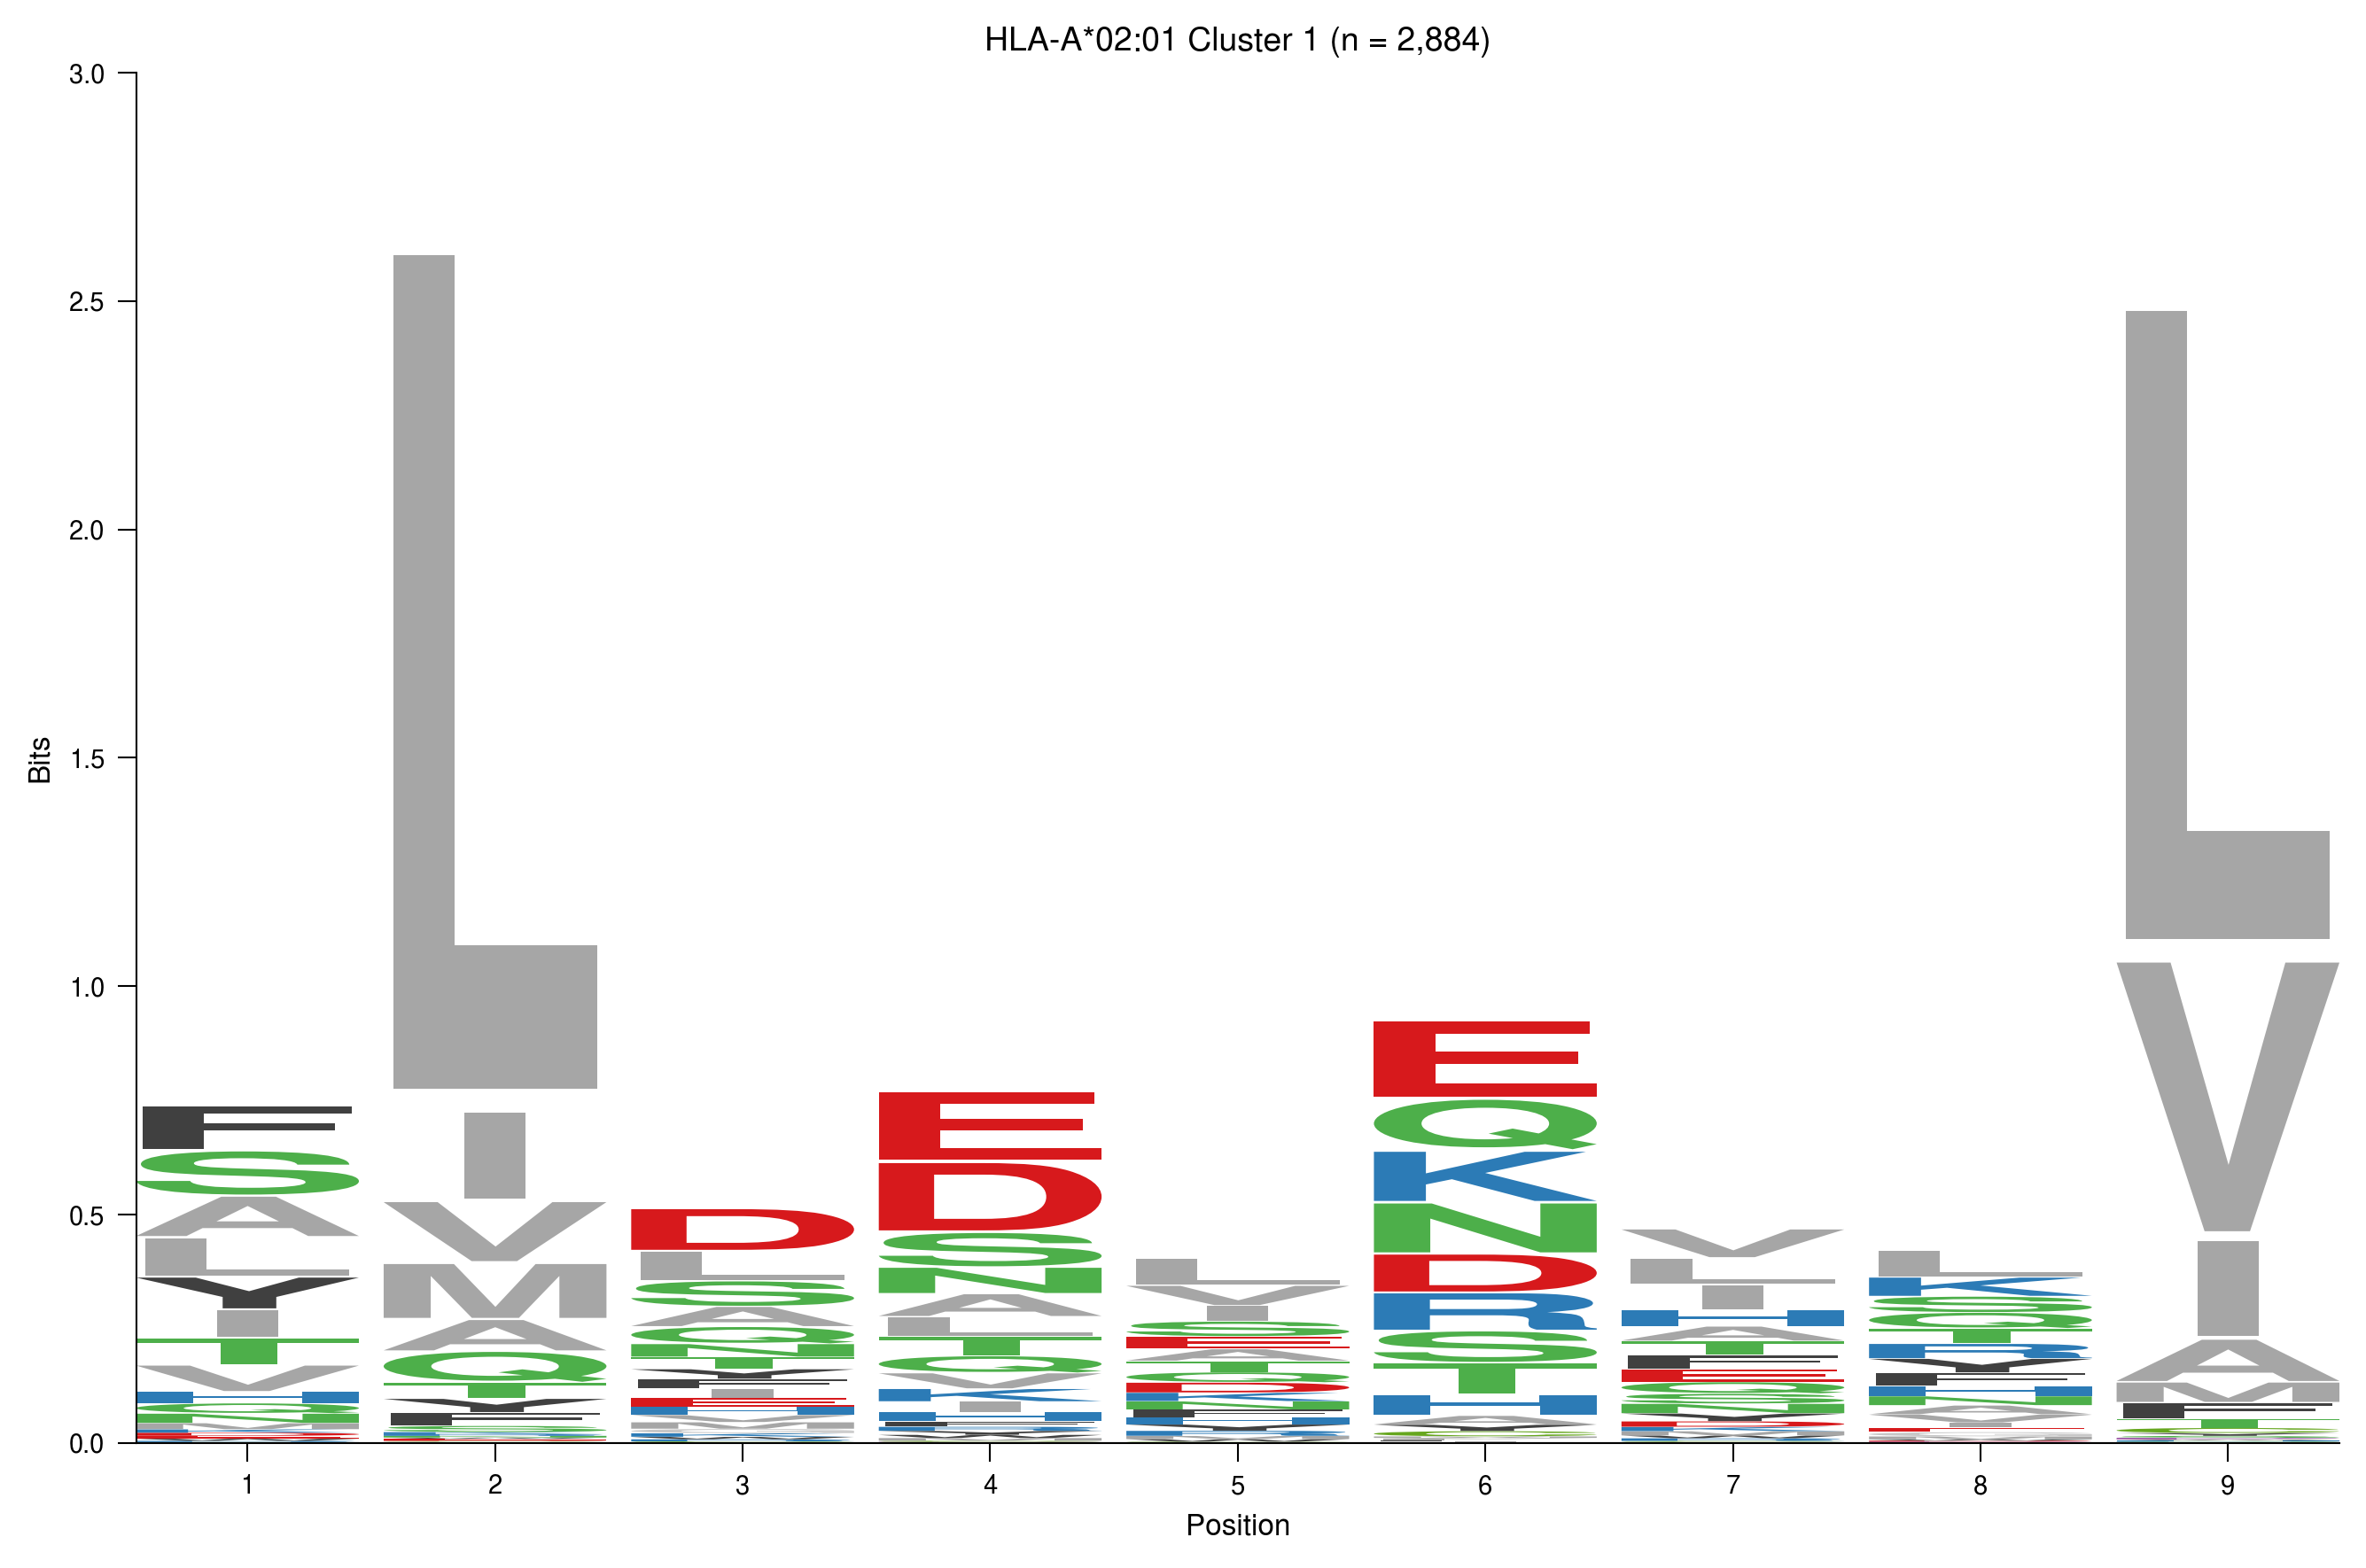

In [ ]:
# a0201 cluster 1 sequence logo plot
plot_pwm_logo_single(
    allele_train_pos_df.query("louvain_id == 1"),
    peptide_col="peptide",
    figsize=(9, 6),
    dpi=300,
    default_font='Nimbus Sans',
    title="HLA-A*02:01 Cluster 1 (n = 2,884)",
    title_fontsize=9,
    title_bold=False,
    show_n_in_title=False,
    ylabel='Bits',
    xlabel='Position',
    xlabel_fontsize=8,
    ylabel_fontsize=8,
    xlabel_pad=4.0,
    ylabel_pad=4.0,
    xtick_labelsize=7,
    ytick_labelsize=7,
    color_scheme=None,
    vpad=0.05,
    logo_width=0.9,
    highlight_cysteine=False,
    cysteine_color='#FF3D3D',
    non_cysteine_color='#D9D9D9',
    ylim=(0, 3.0),
    spine_width=0.5,
    remove_top_right_spines=True,
    tick_length=5.0,
    tick_width=0.5,
    tick_direction='out',
    square_aspect=False,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig3_g_sequence_logo_plot_a0201_cluster_1_for_controllability_test"
)

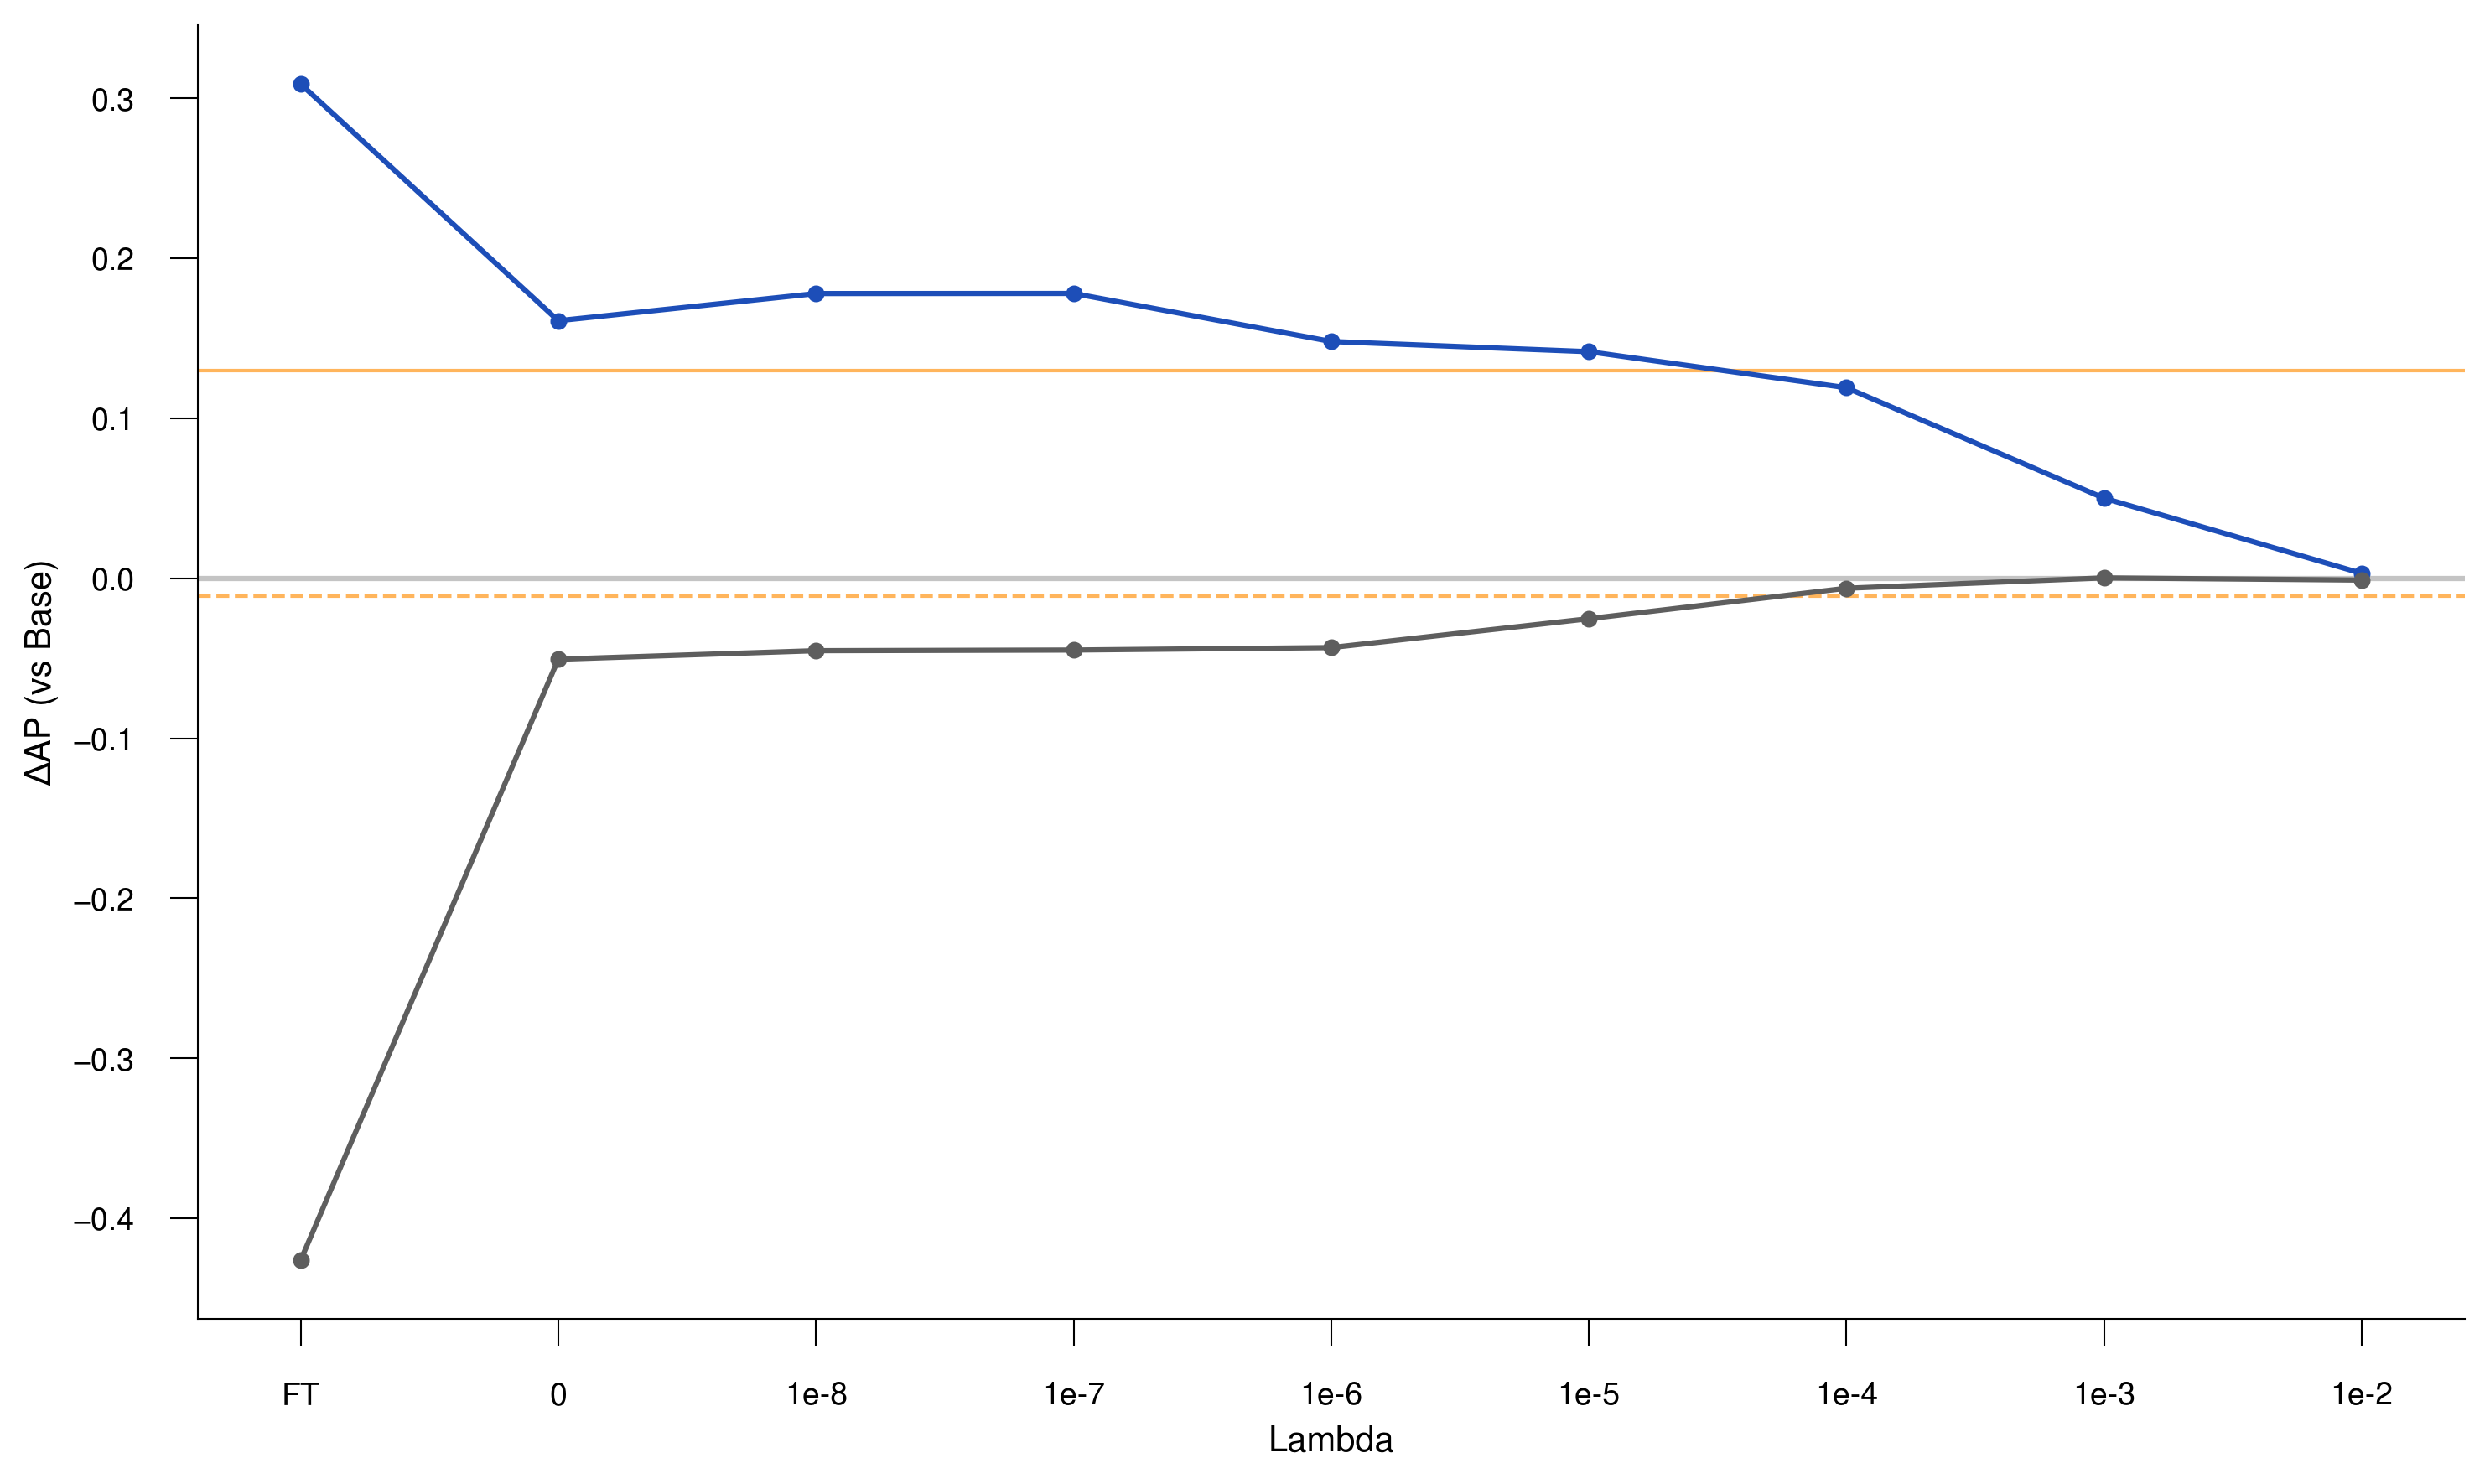

In [ ]:
# plot performance dfs
line_styles = {
    'Base': 
        {
            'cluster': {
                'color': '#C4C4C4',
                'linewidth': 1.0,
                'linestyle': '--',
                'marker': None,
                'alpha': 1.0,
            },
            'prior': {
                'color': '#C4C4C4',
                'linewidth': 1.0,
                'linestyle': '--',
                'marker': None,
                'alpha': 1.0,
            }
        },
        'Full': 
        {
            'cluster': {
                'color': '#FFB55C',
                'linewidth': 1.0,
                'linestyle': '-',
                'marker': None,
                'alpha': 1.0,
            },
            'prior': {
                'color': '#FFB55C',
                'linewidth': 1.0,
                'linestyle': '--',
                'marker': None,
                'alpha': 1.0,
            }
        },
}

plot_cluster_vs_prior_advanced(
    lambda_to_cluster_prior_aps,
    line_styles=line_styles,
    base_color="#C4C4C4",
    full_color='#FFB55C',
    cluster_color='#1D4EB8',
    prior_color='#5E5E5E',
    smooth=False,
    smooth_window=5,
    smooth_poly=2,
    show_markers=True,
    figsize=(10, 6),
    dpi=300,
    default_font='Nimbus Sans',
    xlabel='Lambda',
    ylabel='AP',
    xlabel_fontsize=10,
    ylabel_fontsize=10,
    xlabel_pad=4.0,
    ylabel_pad=4.0,
    title='',
    title_fontsize=12,
    title_bold=True,
    xtick_labelsize=9,
    ytick_labelsize=9,
    tick_length=8.0,
    tick_width=0.5,
    tick_direction='out',
    xtick_rotation=0,
    xtick_ha='center',
    axis_linewidth=0.5,
    xlim=None,
    ylim=None,
    grid_alpha=0.0,
    legend_mode=None,
    legend_loc='upper right',
    legend_bbox=None,
    legend_ncol=None,
    legend_fontsize=8,
    legend_handle_size=1.0,
    delta_base=True,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig3_g_lambda_controllability_test_a0201_cluster_1_line_plots_delta_base"

)

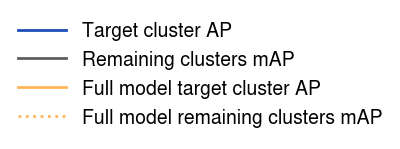

In [ ]:
# plot legend
base_color = "#C4C4C4"
full_color = "#FFB55C"
cluster_color = "#1D4EB8"
prior_color = "#5E5E5E"

line_styles = {
    'Target': {
        'cluster': {'color': cluster_color, 'linewidth': 2.0, 'linestyle': '-', 'marker': None, 'alpha': 1.0},
        'prior': {'color': prior_color,   'linewidth': 2.0, 'linestyle': '-', 'marker': None, 'alpha': 1.0},
    },
    'Full': {
        'cluster': {'color': full_color, 'linewidth': 2.0, 'linestyle': '-', 'marker': None, 'alpha': 1.0},
        'prior': {'color': full_color, 'linewidth': 2.0, 'linestyle': ':', 'marker': None, 'alpha': 1.0},
    },
}

plot_style_legend(
    line_styles,
    labels=[
        "Target cluster AP",
        "Remaining clusters mAP",
        "Full model target cluster AP",
        "Full model remaining clusters mAP",
    ],
    fontsize=14,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig3_g_legend"
)


In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    lambda_to_cluster_prior_aps.to_csv(f"{associated_data_dir}/lambda_to_cluster_prior_aps.csv")

### Fig. 3h: Unseen allele updating

In [ ]:
# ms test set
datasets_dir = DATA_DIR / "Training_Datasets" / "Processed" / "MS_Train_Test_Sets"
ms_test_data=pd.read_csv(f"{datasets_dir}/ms_test_data.csv", index_col=0)

In [ ]:
# remove .pt suffic from any col names
ms_test_data=strip_pt_suffix(ms_test_data)

In [ ]:
# allele splits
allele_holdout_splits_path = DATA_DIR / "Training_Datasets" / "Processed" / "MS_Train_Test_Sets" / "allele_holdout_splits.pkl"
allele_holdout_splits=load_dict_pickle(allele_holdout_splits_path)

In [ ]:
%%time
# get ap matrix
base_model_names=[f"mhcprime_base_aho_split_{str(allele_split)}" for allele_split, allele_list in allele_holdout_splits.items()]
model_ft_names=[f"mhcprime_ft_aho_split_{str(allele_split)}" for allele_split, allele_list in allele_holdout_splits.items()]
model_pepcl_names=[f"mhcprime_pepcl_aho_split_{str(allele_split)}" for allele_split, allele_list in allele_holdout_splits.items()]
score_cols=base_model_names + model_ft_names + model_pepcl_names + ["mhcprime"] # add full model as well

ms_allele_ap_matrix=compute_ap_matrix_optimized(ms_test_data, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)

CPU times: user 15.3 s, sys: 8.58 ms, total: 15.3 s
Wall time: 15.3 s


In [ ]:
ms_allele_map_agg_matrix=compute_aho_split_map_matrix(ms_allele_ap_matrix, allele_holdout_splits, full_col='mhcprime')

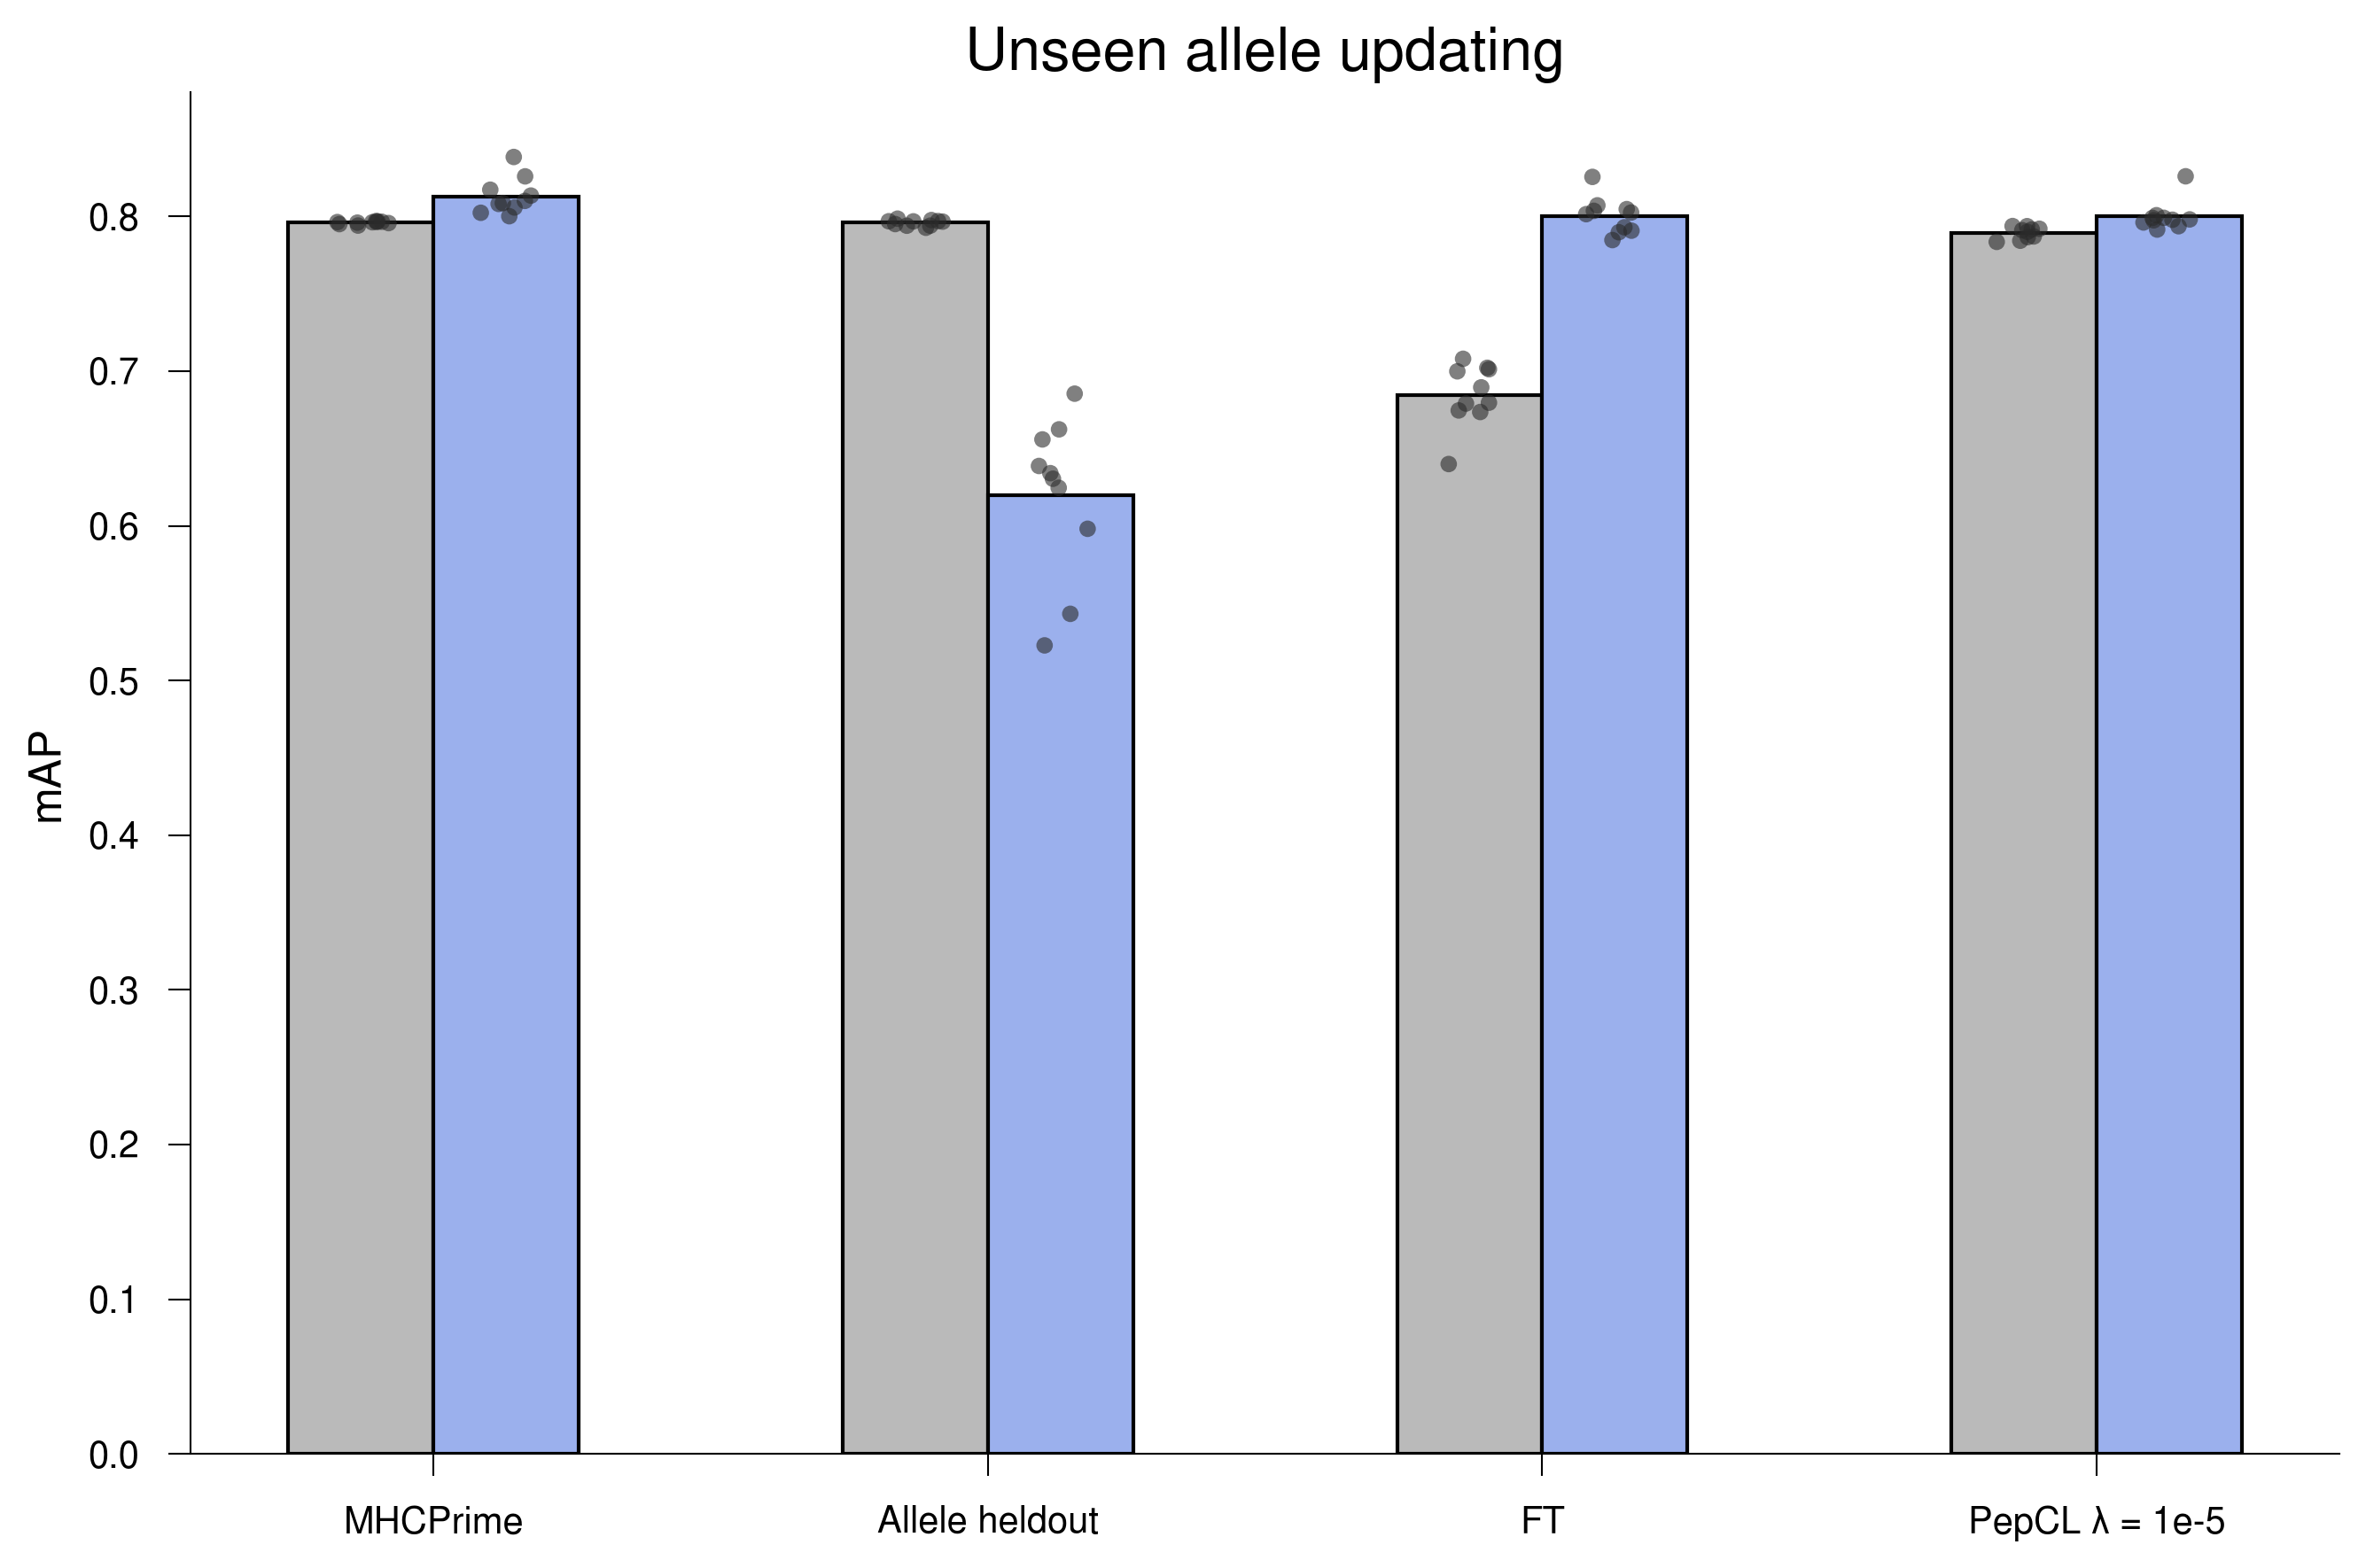

In [ ]:
# plot grouped barplots with jitterplot on top
barplot_groups={
    "MHCPrime": [(ms_allele_map_agg_matrix, "mhcprime_pt_alleles_map"), (ms_allele_map_agg_matrix, "mhcprime_aho_alleles_map")],
    "Allele heldout": [(ms_allele_map_agg_matrix, "model_base_pt_alleles_map"), (ms_allele_map_agg_matrix, "model_base_aho_alleles_map")],
    "FT": [(ms_allele_map_agg_matrix, "model_ft_pt_alleles_map"), (ms_allele_map_agg_matrix, "model_ft_aho_alleles_map")],
    "PepCL λ = 1e-5": [(ms_allele_map_agg_matrix, "model_pepcl_pt_alleles_map"), (ms_allele_map_agg_matrix, "model_pepcl_aho_alleles_map")],
}

target_cluster_color="#9BB0ED"
prior_color="#bababa"

colors={
    "mhcprime_pt_alleles_map": prior_color,
    "model_base_pt_alleles_map": prior_color,
    "model_ft_pt_alleles_map": prior_color,
    "model_pepcl_pt_alleles_map": prior_color,

    "mhcprime_aho_alleles_map": target_cluster_color,
    "model_base_aho_alleles_map": target_cluster_color,
    "model_ft_aho_alleles_map": target_cluster_color,
    "model_pepcl_aho_alleles_map": target_cluster_color,
}

plot_params = {
    'title': 'Unseen allele updating',
    'title_fontsize': 16,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'mAP',
    'xlabel_fontsize': 12,
    'ylabel_fontsize': 12,
    'figsize': (9, 6),
    'dpi': 300,
    'legend_fontsize': 12,
    'legend_cols': 5,
    'legend_handle_size': 0.9,
    'marker_size': 3,
    'axis_linewidth': 0.5,
    'tick_length': 6.0,
    'xlabel_pad': 5.0,
    'ylabel_pad': 5.0,
    'xtick_labelsize': 10,
    'ytick_labelsize': 10

}

pval_df = plot_grouped_barplots_with_jitter(
    barplot_groups,
    colors=colors,
    legend=None,
    plot_params=plot_params,
    ylim=None,
    grid_alpha=0.0,
    default_font='Nimbus Sans',
    bar_width=0.55,
    group_spacing=1.0,
    bar_spacing=0.0,
    bar_outline_color='black',
    bar_outline_width=1.0,
    bar_patch_alpha=1.0,
    bar_agg='mean',
    show_jitter=True,
    jitter_amount=0.20,
    jitter_size=20,
    jitter_color="#2B2B2B",
    jitter_alpha=0.6,
    jitter_edge_color='none',
    jitter_edge_width=0,
    jitter_seed=42,
    hline_y=None,
    hline_label=None,
    hline_color='gray',
    hline_width=1.0,
    hline_style=':',
    hline_text=None,
    hline_text_position='above',
    hline_text_color=None,
    hline_text_fontsize=10,
    hline_text_offset=0.01,
    hline_text_x_offset=0.05,
    hline_in_legend=True,
    reference_hlines=None,
    legend_mode='integrated',
    legend_loc='lower center',
    legend_bbox=None,
    legend_ncol=None,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig3_h_unseen_allele_updating_barplot_w_map_points",
    compute_pvalues=True,
    pvalue_test='wilcoxon',
    cluster_col='louvain_id',
)

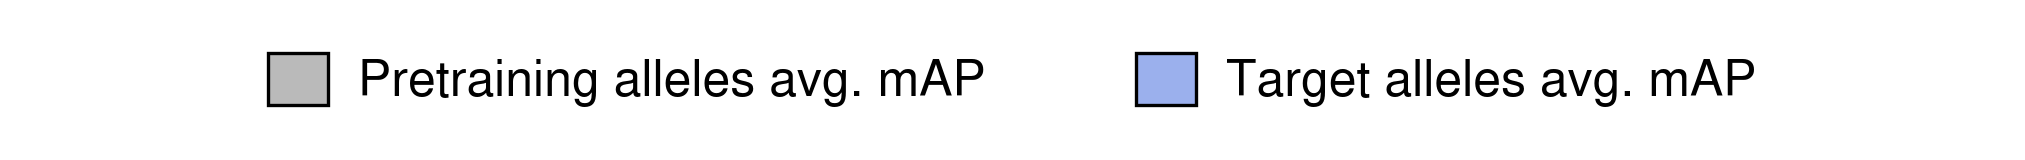

In [ ]:
# legend resized and formatted in illustrator
plot_horizontal_legend(
    legend_dict={
        'Pretraining alleles avg. mAP': '#bababa',
        'Target alleles avg. mAP': '#9bb0ed',
    },
    swatch_size=12,
    text_size=12,
    item_spacing=30,
    swatch_text_gap=6,
    swatch_outline_color='black',
    swatch_outline_width=0.8,
    figsize=None,
    dpi=300,
    default_font='Nimbus Sans',
    save_path=None,
    # save_path=f"{central_figure_dir}/fig3_h_legend",
)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    ms_allele_ap_matrix.to_csv(f"{associated_data_dir}/allele_heldout_per_allele_ap_for_all_models.csv")
    ms_allele_map_agg_matrix.to_csv(f"{associated_data_dir}/allele_heldout_prior_and_split_alleles_map_per_iteration.csv")